# Лекция 1. Языковое моделирование, токенизация и представления слов

Курс «Методы обработки естественного языка». Блокнот рассчитан на Google Colab: ячейки выполняются сверху вниз без дополнительной настройки. Нужны torch, numpy, scipy и matplotlib (в Colab уже есть); для сверки с промышленными реализациями используются `tokenizers`, `sentencepiece` и `transformers`, они тоже предустановлены в Colab. Если какой-то из этих трёх пакетов недоступен, соответствующая ячейка выводит сообщение и не прерывает работу. Корпуса скачиваются автоматически.

Сохранённые выводы получены на CPU в режиме `FAST_DEV_RUN`: меньше эпох для word2vec, меньше скрытое состояние и шагов у RNN. Ветка для GPU в Colab написана, но не проверялась. На ней числа будут другими, переносить стоит направления эффектов.

## Цели лекции

После лекции слушатель должен уметь:

1. записать языковую модель через цепное правило, связать кросс-энтропию, перплексию и длину сжатого кода;
2. объяснить разреженность n-граммных моделей и вероятностный смысл сглаживания Кнезера–Ная;
3. реализовать byte-level BPE и Unigram LM (EM, Viterbi, прунинг) и измерить сжатие, fertility и «налог на токены»;
4. объяснить, почему перплексию нельзя сравнивать между токенизаторами, и перейти к битам на байт;
5. построить PPMI и SVD, вывести оптимум SGNS $w^\top c = \mathrm{PMI}(w,c) - \log k$ и проверить его на данных;
6. вывести градиент softmax с кросс-энтропией и BPTT для простой RNN;
7. оценить норму произведения якобианов RNN, объяснить затухание и взрыв градиентов, роль LSTM и gradient clipping.

## Как устроен блокнот

Часть I «Теория» (разделы 1–5): вероятностная постановка, n-граммы, токенизация, дистрибутивная семантика, нейронные языковые модели. Часть II «Практикум» (разделы 6–16): BPE и Unigram с нуля и сверка с `tokenizers`/`sentencepiece`; сжатие и налог на токены для русского языка, включая токенизаторы GPT-2 и Qwen2.5; PPMI-SVD и SGNS с проверкой теоремы Леви–Голдберга; n-граммы Лапласа и Кнезера–Ная; ручные градиенты; затухание градиентов; символьные RNN и LSTM. В конце — выводы, контрольные вопросы, задания и источники.

Практикум соответствует лабораторным 1–3 курса. Здесь показан минимальный рабочий вариант каждого эксперимента, в лабораторных их нужно расширить.

## Корпуса

- «Анна Каренина» Л. Н. Толстого на русском ([RusLit](https://github.com/d0rj/RusLit)) и в английском переводе ([Project Gutenberg](https://www.gutenberg.org/ebooks/1399)). Один и тот же роман на двух языках позволяет честно сравнивать токенизаторы: содержание одинаковое, различаются только язык и письменность.
- Английский перевод «Войны и мира» ([Project Gutenberg](https://www.gutenberg.org/ebooks/2600)) — дополнительный текст для эмбеддингов слов.
- Tiny Shakespeare, около 1 млн символов ([Karpathy, char-rnn](https://github.com/karpathy/char-rnn)) — для символьных языковых моделей. На нём же в лекции 2 обучается Mini-GPT, так что результаты двух лекций можно сравнить.

## Обозначения

| Символ | Смысл |
|---|---|
| $x_{1:T}$ | последовательность токенов (символов, подслов, слов) |
| $\mathcal{V}$, $V$ | словарь и его размер |
| $p_\theta(x_t \mid x_{<t})$ | условное распределение модели |
| $H(p, q)$ | кросс-энтропия, в битах при $\log_2$ |
| $\#(w)$, $\#(w, c)$ | число вхождений слова и пары (слово, контекст) |
| $\mathrm{PMI}(w, c)$ | поточечная взаимная информация |
| $W, C$ | матрицы векторов слов и контекстов в word2vec |
| $k$ | число отрицательных примеров в SGNS |
| $z$, $p = \mathrm{softmax}(z)$, $e_y$ | логиты, вероятности, one-hot правильного класса |
| $h_t$, $W_{hh}$ | скрытое состояние RNN и матрица рекуррентных весов |
| $\sigma_{\max}(A)$, $\rho(A)$ | наибольшее сингулярное число и спектральный радиус |

# Часть I. Теория

## 1. Язык как распределение вероятностей

### 1.1. Цепное правило

Языковая модель задаёт распределение над конечными последовательностями токенов $x_{1:T}$ из словаря $\mathcal{V}$. Любое такое распределение раскладывается по цепному правилу:

$
p(x_{1:T}) = \prod_{t=1}^{T} p(x_t \mid x_{<t}),
$

где $x_T$ — специальный токен конца последовательности. Это не приближение, а тождество. Приближения начинаются, когда условное распределение $p(x_t \mid x_{<t})$ параметризуют: таблицей для последних $n-1$ токенов (n-граммы, раздел 2), рекуррентным состоянием (раздел 5) или вниманием ко всему префиксу (лекция 2). Генерация в такой модели — последовательное сэмплирование $x_t \sim p(\cdot \mid x_{<t})$.

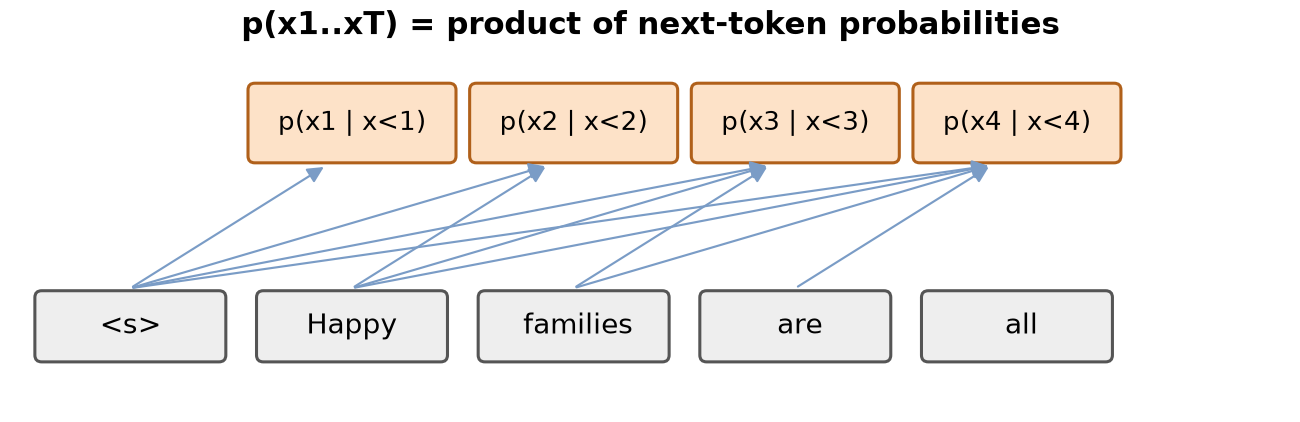

### 1.2. MLE и кросс-энтропия

Пусть корпус $\mathcal{D}$ содержит $N$ токенов. Метод максимального правдоподобия минимизирует

$
\mathcal{L}(\theta) = -\frac{1}{N}\sum_{t=1}^{N}\log p_\theta(x_t \mid x_{<t}).
$

Если текст порождён стационарным эргодическим источником $P$, то при $N\to\infty$ это эмпирическое среднее сходится к кросс-энтропии $H(P, p_\theta)$ на токен. Кросс-энтропия раскладывается так:

$
H(P, p_\theta) = H(P) + D_{\mathrm{KL}}(P \,\|\, p_\theta) \ge H(P).
$

Энтропия источника $H(P)$ от модели не зависит. Поэтому минимизация потерь эквивалентна минимизации KL-дивергенции от истинного распределения, и потерю нельзя опустить ниже энтропии самого языка.

### 1.3. Перплексия

Перплексия — экспонента кросс-энтропии:

$
\mathrm{PPL} = \exp\!\Big(-\frac{1}{N}\sum_t \ln p_\theta(x_t \mid x_{<t})\Big) = 2^{\,H_2},
$

где $H_2$ — та же величина в битах. Перплексия — эффективное число равновероятных вариантов, между которыми модель в среднем выбирает. У равномерной модели на $V$ символах $\mathrm{PPL} = V$. Если модель хотя бы одному токену теста приписала нулевую вероятность, перплексия бесконечна. Отсюда необходимость сглаживания (раздел 2.2).

### 1.4. Предсказание — это сжатие

По теореме Шеннона об источнике средняя длина префиксного кода не меньше энтропии. Арифметическое кодирование по модели $p_\theta$ достигает длины $-\log_2 p_\theta(x_{1:T}) + 2$ бита на всю последовательность ([Shannon, 1948](https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf)). Значит, кросс-энтропия в битах на символ — это буквально число бит на символ, которое займёт текст, сжатый с помощью модели. Хорошая языковая модель является хорошим компрессором, и наоборот. Пример силы этой связи: Chinchilla 70B, обученная в основном на тексте, через арифметическое кодирование сжимает фрагменты ImageNet до 43.4% исходного размера, а LibriSpeech — до 16.4%. Это лучше PNG (58.5%) и FLAC (30.3%) ([Delétang et al., 2023](https://arxiv.org/abs/2309.10668)).

Для ориентира: Шеннон, опираясь на опыты по угадыванию следующей буквы людьми, оценил энтропию печатного английского текста при контексте в 100 букв в пределах от 0.6 до 1.3 бита на букву ([Shannon, 1951](https://onlinelibrary.wiley.com/doi/abs/10.1002/j.1538-7305.1951.tb01366.x)). У равномерного распределения на 27 символах — $\log_2 27 \approx 4.75$ бита. Разница — избыточность языка, которую и использует модель.

### 1.5. Единица измерения зависит от токенизации

Перплексию считают на токен. Если одна модель режет текст на символы, а другая на подслова, их токенные перплексии измерены в разных единицах и несравнимы. Сравнимая величина — суммарная $-\log_2 p$ всего текста, делённая на его длину в байтах (bits-per-byte, bpb) или символах:

$
\text{bpb} = \frac{N_{\text{tok}}}{N_{\text{bytes}}}\cdot H_2^{\text{tok}} .
$

Эта величина не зависит от того, как текст разбит на токены ([Mielke et al., 2021](https://arxiv.org/abs/2112.10508)). В разделе 12.1 токенная биграмма над BPE-1000 имеет перплексию 55 на токен, а символьная — 12 на символ. По перплексии токенная модель выглядит вчетверо хуже, а в битах на символ она лучше: 2,59 против 3,58.

## 2. N-граммные модели

### 2.1. Марковское предположение и разреженность

N-граммная модель предполагает, что $p(x_t \mid x_{<t}) = p(x_t \mid x_{t-n+1:t-1})$. Оценка MLE — относительная частота:

$
\hat p(w \mid h) = \frac{\#(h w)}{\#(h)} .
$

Число возможных контекстов растёт как $V^{n-1}$, а корпус конечен. Поэтому почти все длинные контексты либо не встречаются, либо встречаются один-два раза. Тогда MLE даёт нулевую вероятность всему, чего не было в обучении. Отсюда компромисс: маленькое $n$ — грубая модель, большое $n$ — переобучение. В разделе 12 видно, что качество на обучении монотонно улучшается с ростом $n$, а на валидации после $n \approx 5$–6 начинает ухудшаться.

### 2.2. Сглаживание Лапласа

Добавим к каждому счётчику единицу:

$
\hat p_{\text{add-1}}(w \mid h) = \frac{\#(hw) + 1}{\#(h) + V}.
$

Байесовская интерпретация: это апостериорное среднее при априорном распределении Дирихле $\mathrm{Dir}(1,\dots,1)$ на $p(\cdot \mid h)$. Недостаток: для редкого контекста с $\#(h) \ll V$ почти вся масса уходит в псевдосчётчики. Например, у контекста, встреченного 3 раза, при $V = 65$ на наблюдаемые продолжения приходится меньше 6% массы. В разделе 12 это видно: Лаплас хуже Кнезера–Ная уже при $n = 3$ и катастрофически хуже при $n \ge 5$.

### 2.3. Сглаживание Кнезера–Ная

Две идеи.

1. **Абсолютная скидка.** Из каждого ненулевого счётчика вычитаем константу $D \in (0,1)$. Освободившуюся массу $D \cdot N_{1+}(h\bullet)/\#(h)$, где $N_{1+}(h\bullet)$ — число различных продолжений $h$, отдаём модели меньшего порядка. Обоснование: счётчики, встреченные $r$ раз в обучении, в среднем встречаются примерно $r - 0.75$ раз в новых данных того же объёма (оценка Гуда–Тьюринга). Отсюда $D \approx 0.75$. Оценку $D = n_1/(n_1 + 2n_2)$ дают из правдоподобия по схеме leave-one-out; её и используем в практикуме.
2. **Счётчики продолжений.** Модель меньшего порядка используется только тогда, когда старший контекст неизвестен. Поэтому важна не частота $w$, а то, в скольких различных контекстах $w$ встречается. Классический пример: «Francisco» частое слово, но почти всегда после «San». Как продолжение нового контекста оно маловероятно. Поэтому младшие порядки оцениваются по $N_{1+}(\bullet\, w) = |\{v : \#(vw) > 0\}|$.

Интерполированная формула (рекурсия по порядку):

$
p_{\mathrm{KN}}(w \mid h) = \frac{\max(\#(hw) - D, 0)}{\#(h)} + \frac{D\, N_{1+}(h\bullet)}{\#(h)}\; p_{\mathrm{KN}}(w \mid h'),
$

где $h'$ — контекст без первого символа. В младших порядках $\#$ заменяется на счётчик продолжений. Модель корректно нормирована при любом $D$: сумма первого слагаемого по $w$ равна $1 - D N_{1+}(h\bullet)/\#(h)$, а второе добавляет недостающее. Вариант с тремя скидками (для $r = 1, 2, \ge 3$) — modified KN — был лучшим методом в обширном сравнении Чена и Гудмана ([Chen & Goodman, 1998](https://dash.harvard.edu/entities/publication/73120378-fb0f-6bd4-e053-0100007fdf3b); [Kneser & Ney, 1995](https://www-i6.informatik.rwth-aachen.de/publications/download/951/Kneser-ICASSP-1995.pdf)). Подробное изложение — в главе 3 учебника Jurafsky и Martin ([SLP3](https://web.stanford.edu/~jurafsky/slp3/)).

## 3. Токенизация

### 3.1. Слова, символы, подслова

Токенизация выбирает алфавит, над которым определена языковая модель. Варианты:

- **Слова.** Короткие последовательности, но словарь открытый: в русском у существительного до 12 форм, у глагола — десятки. Любое новое слово превращается в `<unk>`.
- **Символы или байты.** Словарь маленький и закрытый (256 байтов покрывают любой текст), но последовательности в 4–5 раз длиннее. Для трансформера с вниманием $O(T^2)$ (лекция 2) это дорого.
- **Подслова.** Частые слова — один токен, редкие — несколько осмысленных частей. Словарь от $10^4$ до $2.5\cdot 10^5$, и он закрыт, если нижний уровень — байты.

Подсловная токенизация — компромисс между длиной последовательности $N_{\text{tok}}$ и размером словаря $V$. Обе величины влияют на стоимость модели: $N_{\text{tok}}$ — на число шагов и длину контекста, $V$ — на размер матриц эмбеддингов и выходного softmax.

### 3.2. BPE как жадное сжатие

Byte Pair Encoding пришёл из сжатия данных ([Gage, 1994](https://www.semanticscholar.org/paper/A-new-algorithm-for-data-compression-Gage/1aa9c0045f1fe8c79cce03c7c14ef4b4643a21f8)). Для перевода его адаптировали Sennrich и соавторы ([Sennrich et al., 2016](https://arxiv.org/abs/1508.07909)). Обучение:

1. разбить текст на претокены (примерно слова с ведущим пробелом), каждый претокен — последовательность базовых символов;
2. посчитать частоты всех соседних пар символов с учётом частоты претокенов;
3. объединить самую частую пару $(a, b)$ в новый символ $ab$, добавить правило в список слияний;
4. повторять, пока словарь не достигнет размера $V$.

Каждое слияние уменьшает длину корпуса ровно на частоту объединённой пары. Значит, BPE — жадный алгоритм для задачи «выбрать $V - 256$ правил, минимизирующих длину корпуса». Жадность не гарантирует оптимума. Поиск оптимальной последовательности слияний — APX-полная задача, а гарантированная доля оптимального сжатия у жадного BPE в худшем случае лежит между 0.333 и 0.625 ([Kozma & Voderholzer, 2024](https://arxiv.org/abs/2411.08671)). Кодирование нового текста применяет слияния в порядке их появления при обучении. Поэтому словарь меньшего размера — просто префикс списка слияний (раздел 9).

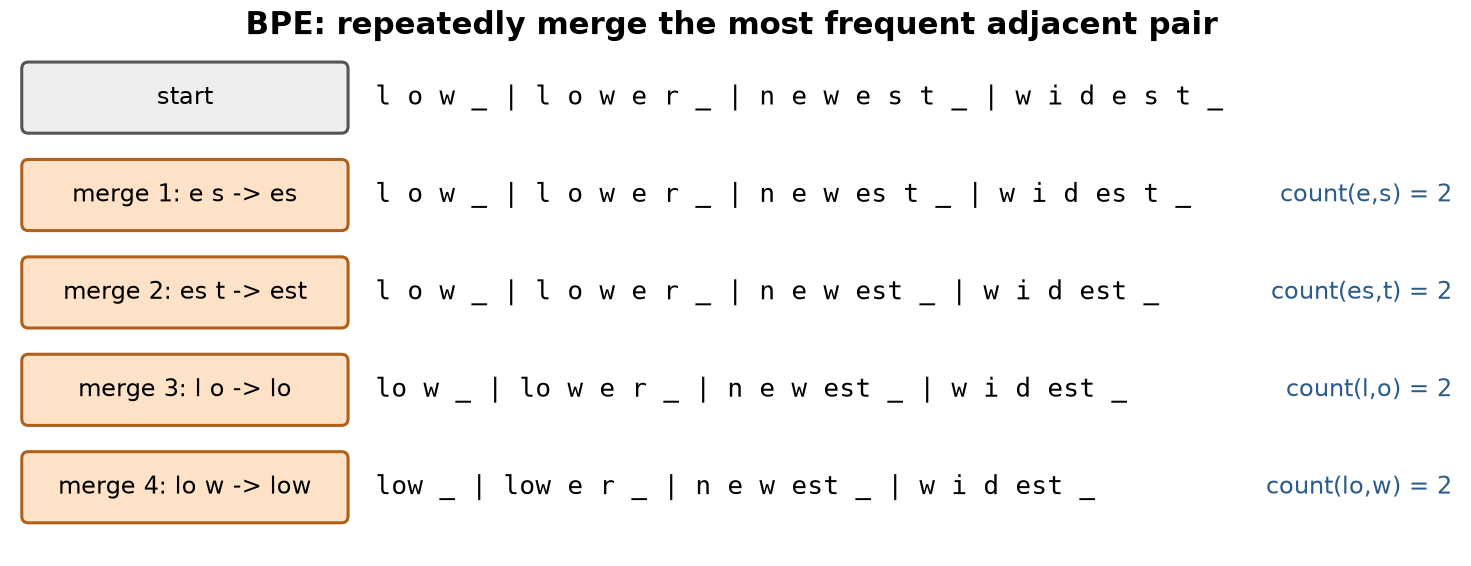

**Byte-level BPE.** GPT-2 строит BPE не над символами Unicode, а над байтами UTF-8 ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)). Базовый словарь — 256 байтов, поэтому токенизатор кодирует любую строку без `<unk>`, и декодирование точно обратно кодированию. Цена — кириллическая буква в UTF-8 занимает 2 байта, и первые слияния русского BPE тратятся на склейку этих пар (раздел 7). Претокенизация регулярным выражением не даёт слияниям пересекать границы слов, цифр и знаков препинания.

**WordPiece** ([Schuster & Nakajima, 2012](https://research.google/pubs/japanese-and-korean-voice-search/)) — тот же жадный процесс, но пара выбирается не по частоте, а по приросту правдоподобия униграммной модели корпуса. На практике пару выбирают по оценке $\#(ab) / (\#(a)\,\#(b))$; такой критерий приводится в курсе Hugging Face ([Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter6/6)). По сути это PMI пары. WordPiece используется в BERT.

### 3.3. Unigram LM

Unigram LM идёт с другой стороны ([Kudo, 2018](https://arxiv.org/abs/1804.10959)). Предполагается, что претокен $x$ порождается как последовательность независимых подслов $\mathbf{u} = (u_1,\dots,u_m)$ из словаря $\mathcal{V}$ с вероятностями $p(u)$, $\sum_u p(u) = 1$:

$
p(x) = \sum_{\mathbf{u} \in S(x)} \prod_{i} p(u_i),
$

где $S(x)$ — все сегментации $x$ на подслова словаря. Сегментации образуют решётку (lattice): вершины — позиции в строке, рёбра — подслова.

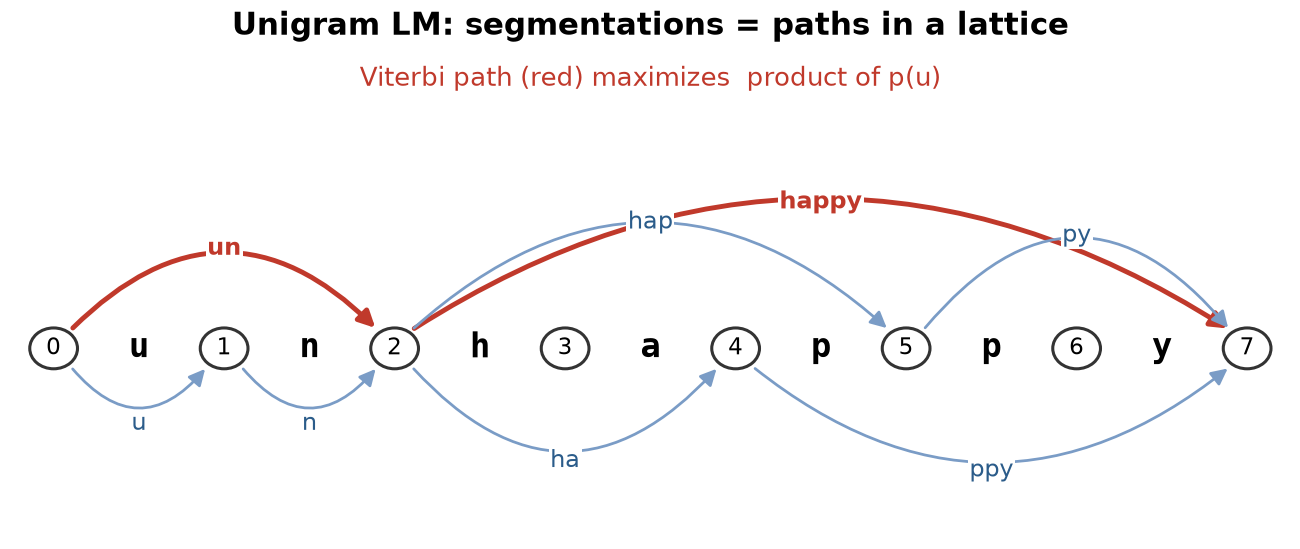

- **Кодирование** — сегментация максимальной вероятности $\arg\max_{\mathbf{u}} \prod p(u_i)$, алгоритм Витерби по решётке за $O(L \cdot \ell_{\max})$.
- **Обучение** при фиксированном словаре — EM. E-шаг: прямой-обратный проход по решётке даёт ожидаемое число вхождений каждого подслова $\mathbb{E}[\#u]$. M-шаг: $p(u) \propto \mathbb{E}[\#u]$.
- **Выбор словаря.** Начинаем с большого множества кандидатов (частые подстроки). Для каждого подслова оцениваем, насколько упадёт правдоподобие корпуса, если его удалить. Удаляем 25% наименее полезных, повторяем EM. Отдельные символы не удаляем никогда, чтобы любое слово оставалось представимым.
- **Subword regularization.** На обучении модели можно сэмплировать сегментацию из $p(\mathbf{u}\mid x)^\alpha$ вместо Витерби. Модель видит одно слово в разных разбиениях, и это работает как аугментация ([Kudo, 2018](https://arxiv.org/abs/1804.10959)).

Реализация Unigram в SentencePiece работает с сырым текстом, а пробел кодирует символом «▁», так что токенизация обратима без внешней претокенизации ([Kudo & Richardson, 2018](https://arxiv.org/abs/1808.06226)).

### 3.4. Что токенизация делает с моделью

- **Налог на токены.** Токенизатор, обученный в основном на английском, режет русский текст гораздо мельче. Тогда тот же смысл стоит больше токенов: дороже API, меньше эффективный контекст, медленнее генерация. Petrov и соавторы показали, что для одного и того же текста длина в токенах у разных языков различается до 15 раз ([Petrov et al., 2023](https://arxiv.org/abs/2305.15425)). Мы измерим это на «Анне Карениной» (раздел 9.1).
- **Числа.** Если цифры объединяются слияниями BPE, одинаковые по длине числа режутся по-разному, и модели трудно выучить поразрядную арифметику. Поэтому в LLaMA все числа разбиты на отдельные цифры ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)).
- **Сравнение моделей.** Перплексия на токен зависит от токенизатора (раздел 1.5). Сравнивать модели с разными токенизаторами можно только в битах на байт или символ.
- **Редкие токены.** Токен, встретившийся в обучающих данных модели несколько раз, получает почти необученный эмбеддинг. Такие «застрявшие» токены вызывают странное поведение LLM ([Land & Bartolo, 2024](https://arxiv.org/abs/2405.05417)).

## 4. Дистрибутивная семантика

### 4.1. Матрица совместной встречаемости и PMI

Дистрибутивная гипотеза: слова, встречающиеся в похожих контекстах, имеют похожие значения ([Harris, 1954](https://doi.org/10.1080/00437956.1954.11659520); обзор — глава 6 [SLP3](https://web.stanford.edu/~jurafsky/slp3/)). Формализация: матрица $M \in \mathbb{R}^{V\times V}$, где $M_{wc} = \#(w, c)$ — сколько раз слово $c$ стояло в окне $\pm L$ вокруг $w$. Сырые счётчики плохи: в них доминируют частые служебные слова. Нормировка — поточечная взаимная информация:

$
\mathrm{PMI}(w, c) = \log\frac{P(w, c)}{P(w)\,P(c)} = \log\frac{\#(w,c)\cdot |D|}{\#(w)\,\#(c)},
$

где $|D|$ — число пар. PMI положительна, если пара встречается чаще, чем при независимости. Для ненаблюдавшихся пар $\mathrm{PMI} = -\infty$, поэтому на практике берут PPMI $= \max(\mathrm{PMI}, 0)$. PMI завышена для редких контекстов. Сглаживание распределения контекстов $P_\alpha(c) \propto \#(c)^{\alpha}$, $\alpha = 0.75$, заимствованное из word2vec, заметно улучшает счётные методы ([Levy et al., 2015](https://aclanthology.org/Q15-1016/)).

### 4.2. SVD

Усечённое SVD $\mathrm{PPMI} \approx U_d \Sigma_d V_d^\top$ — наилучшее приближение ранга $d$ по норме Фробениуса (теорема Эккарта–Янга). Векторы слов берут как $W = U_d \Sigma_d^{p}$; при $p = 1/2$ скалярное произведение $W W_c^\top$ воспроизводит матрицу, при $p = 0$ получается более равномерное по компонентам пространство. Подбор $p$ и других «гиперпараметров счётных методов» во многом объясняет, почему word2vec когда-то казался сильнее SVD ([Levy et al., 2015](https://aclanthology.org/Q15-1016/)).

### 4.3. Word2vec и оптимум SGNS

Skip-gram ([Mikolov et al., 2013a](https://arxiv.org/abs/1301.3781)) предсказывает контекст по центральному слову: $p(c \mid w) = \mathrm{softmax}_c(w^\top c)$ с двумя матрицами векторов — для слов $W$ и для контекстов $C$. Нормировка по всему словарю дорогая. Negative sampling ([Mikolov et al., 2013b](https://arxiv.org/abs/1310.4546)) заменяет её на $k+1$ логистических задач: настоящая пара против $k$ случайных контекстов из $P_\alpha$:

$
\ell(w, c) = -\log\sigma(w^\top c) - \sum_{i=1}^{k}\log\sigma(-w^\top n_i), \qquad n_i \sim P_\alpha .
$

CBOW — обратная задача: предсказать центральное слово по среднему векторов контекста.

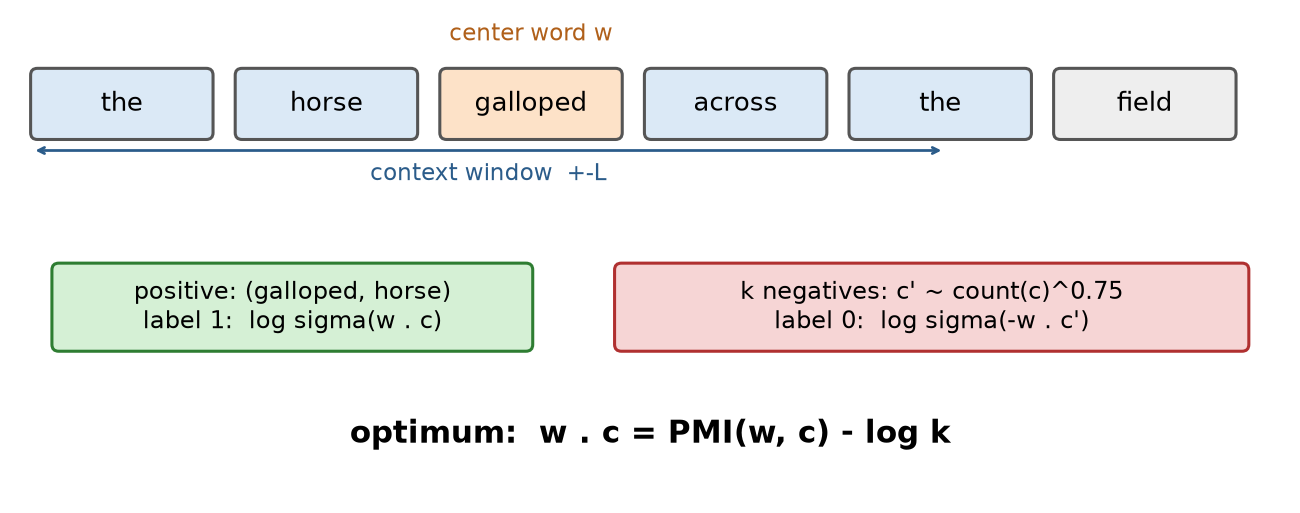

**Теорема Леви–Голдберга.** Просуммируем потери по корпусу и сгруппируем по парам. Для фиксированной пары $(w, c)$ с $x = w^\top c$ в сумму входят $\#(w,c)$ положительных слагаемых и, в среднем, $k\,\#(w)\,P_\alpha(c)$ отрицательных:

$
\ell_{wc}(x) = -\#(w,c)\log\sigma(x) - k\,\#(w)\,P_\alpha(c)\,\log\sigma(-x).
$

Используем $\frac{d}{dx}\log\sigma(x) = 1 - \sigma(x)$ и $\frac{d}{dx}\log\sigma(-x) = -\sigma(x)$, приравниваем производную нулю:

$
-\#(w,c)\,(1-\sigma(x)) + k\,\#(w)\,P_\alpha(c)\,\sigma(x) = 0
\;\Rightarrow\;
\frac{\sigma(x)}{1-\sigma(x)} = e^{x} = \frac{\#(w,c)}{k\,\#(w)\,P_\alpha(c)} .
$

Значит,

$
w^\top c = \log\frac{\#(w,c)}{\#(w)\,P_\alpha(c)} - \log k = \mathrm{PMI}_\alpha(w,c) - \log k .
$

Если размерность позволяет подобрать все $w^\top c$ независимо, SGNS неявно факторизует матрицу PMI, сдвинутую на $\log k$ ([Levy & Goldberg, 2014](https://papers.nips.cc/paper_files/paper/2014/hash/b78666971ceae55a8e87efb7cbfd9ad4-Abstract.html)). При $d \ll V$ это взвешенная факторизация низкого ранга: частые пары весят больше. В разделе 11.4 проверим, насколько обученные $w^\top c$ близки к этой цели.

### 4.4. GloVe

GloVe минимизирует взвешенную квадратичную ошибку $\sum_{w,c} f(\#(w,c))\,(w^\top \tilde c + b_w + \tilde b_c - \log \#(w,c))^2$. Весовая функция $f$ обрезает влияние очень частых пар и обнуляет нулевые ([Pennington et al., 2014](https://nlp.stanford.edu/pubs/glove.pdf)). Смещения $b_w, \tilde b_c$ поглощают $\log\#(w)$ и $\log\#(c)$, так что по существу это тоже факторизация PMI, но явная и по ненулевым ячейкам.

### 4.5. Геометрия: аналогии и анизотропия

Аналогия «$a : a^* = b : b^*$» решается как $b^* = \arg\max_x \cos(x,\, b - a + a^*)$ (3CosAdd). Это работает, если разность $a^* - a$ примерно одинакова для всех пар с одним отношением. В терминах PMI это требует, чтобы отношение $P(c \mid a^*)/P(c \mid a)$ мало зависело от выбора пары; аналогичное условие обсуждают авторы GloVe ([Pennington et al., 2014](https://nlp.stanford.edu/pubs/glove.pdf)).

Векторы SGNS не заполняют пространство равномерно: они лежат в узком конусе, противоположном векторам контекстов, и средний косинус случайных слов заметно положителен ([Mimno & Thompson, 2017](https://aclanthology.org/D17-1308/)). Вычитание среднего вектора и удаление нескольких главных компонент улучшает качество на задачах сходства ([Mu & Viswanath, 2018](https://arxiv.org/abs/1702.01417)).

## 5. Нейронные языковые модели

### 5.1. Модель Бенджио и градиент softmax

Нейронная языковая модель Бенджио и соавторов ([Bengio et al., 2003](https://jmlr.org/papers/v3/bengio03a.html)) отображает $n-1$ предыдущих слов в векторы, склеивает их, пропускает через скрытый слой и softmax по словарю. Главная идея: похожие слова получают похожие векторы, и вероятность обобщается на невиданные n-граммы без явного сглаживания.

Градиент выходного слоя одинаков для всех таких моделей. Пусть $z \in \mathbb{R}^V$ — логиты, $p = \mathrm{softmax}(z)$, $\ell = -\log p_y = -z_y + \log\sum_j e^{z_j}$. Тогда

$
\frac{\partial \ell}{\partial z_i} = -\mathbb{1}[i = y] + \frac{e^{z_i}}{\sum_j e^{z_j}} = p_i - \mathbb{1}[i = y],
\qquad \nabla_z \ell = p - e_y .
$

Свойства: сумма компонент градиента равна нулю (softmax инвариантен к сдвигу логитов), норма не больше $\sqrt{2}$, градиент обращается в ноль только при $p = e_y$. Якобиан самого softmax равен $\partial p_i/\partial z_j = p_i(\mathbb{1}[i=j] - p_j)$, то есть $J = \mathrm{diag}(p) - pp^\top$. Он вырождается при насыщении, когда $p$ близко к one-hot; это понадобится в лекции 2 для обоснования масштаба $1/\sqrt{d_k}$ в attention.

### 5.2. Рекуррентная сеть и BPTT

Простая RNN ([Elman, 1990](https://doi.org/10.1207/s15516709cog1402_1); языковая модель на RNN — [Mikolov et al., 2010](https://www.isca-archive.org/interspeech_2010/mikolov10_interspeech.html)):

$
h_t = \tanh(W h_{t-1} + U x_t + b), \qquad p(x_{t+1} \mid x_{\le t}) = \mathrm{softmax}(V h_t + c).
$

Контекст больше не обрезан: $h_t$ в принципе зависит от всего префикса. Обучение — обратное распространение через развёрнутый граф (BPTT). Формулы приведены в разделе 13.2.

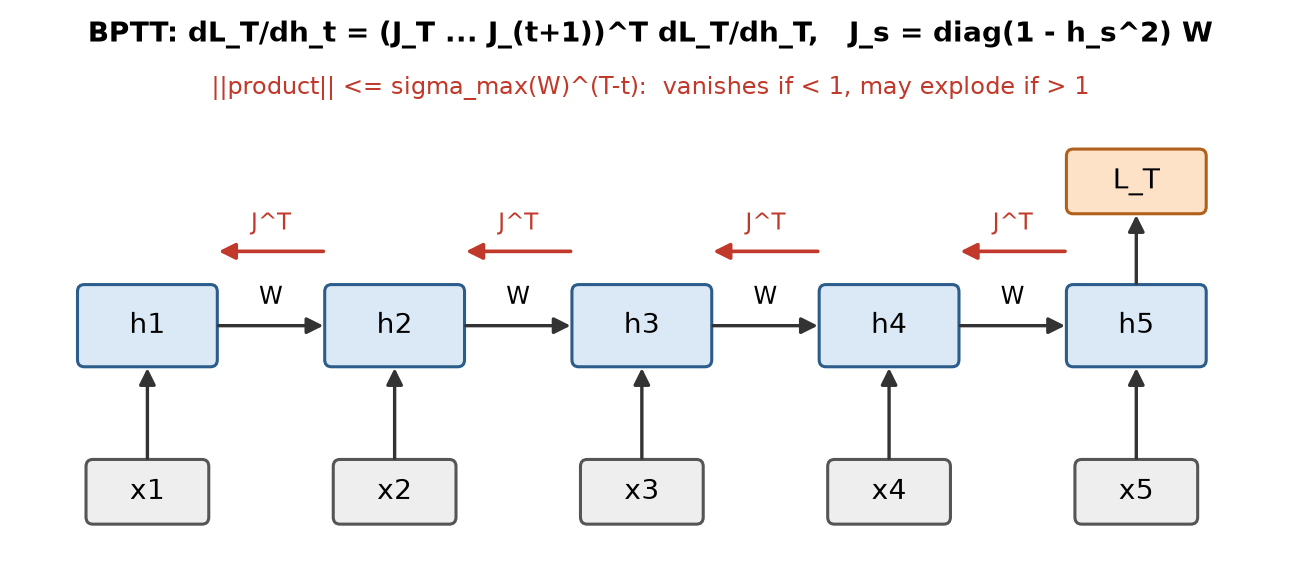

### 5.3. Затухание и взрыв градиентов

Вклад потери на шаге $T$ в градиент по $h_t$:

$
\frac{\partial L_T}{\partial h_t} = \Big(\prod_{s=t+1}^{T} J_s\Big)^{\!\top} \frac{\partial L_T}{\partial h_T}, \qquad J_s = \frac{\partial h_s}{\partial h_{s-1}} = \mathrm{diag}(1 - h_s^2)\,W .
$

Из субмультипликативности нормы и $|\tanh'| \le 1$:

$
\Big\|\frac{\partial L_T}{\partial h_t}\Big\| \le \big(\sigma_{\max}(W)\big)^{T-t}\,\Big\|\frac{\partial L_T}{\partial h_T}\Big\| .
$

Достаточное условие затухания: $\sigma_{\max}(W) < 1$. Тогда градиент от далёких шагов экспоненциально мал, и модель не учится долгим зависимостям. Необходимое условие взрыва: $\sigma_{\max}(W) > 1$, иначе произведение ограничено ([Pascanu et al., 2013](https://arxiv.org/abs/1211.5063); [Bengio et al., 1994](https://doi.org/10.1109/72.279181)). Для линейной RNN с ортогональной $W = \rho Q$ норма меняется ровно как $\rho^{T-t}$; это проверяется в разделе 14. Нелинейность $\tanh$ только уменьшает производные, поэтому при насыщении взрыва может не быть даже при $\rho > 1$.

Асимптотику при больших $T - t$ определяет спектральный радиус $\rho(W)$, а $\sigma_{\max}$ — только верхнюю оценку. Для несимметричной матрицы $\rho(W) \le \sigma_{\max}(W)$, и при $\rho < 1 < \sigma_{\max}$ возможен временный рост нормы на коротких расстояниях (раздел 14.1).

**Gradient clipping.** Если $\|g\| > \tau$, градиент заменяют на $\tau g/\|g\|$ ([Pascanu et al., 2013](https://arxiv.org/abs/1211.5063)). Направление сохраняется, а длина шага ограничена. Это лечит взрыв, но не затухание.

### 5.4. LSTM

LSTM ([Hochreiter & Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735)) с гейтом забывания ([Gers et al., 2000](https://doi.org/10.1162/089976600300015015)) вводит ячейку памяти с аддитивным обновлением:

$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t),
$

где $f_t, i_t, o_t \in (0,1)^d$ — гейты (сигмоиды от $x_t, h_{t-1}$). По прямому пути через ячейку $\partial c_t / \partial c_{t-1} = \mathrm{diag}(f_t)$: вместо произведения матриц — произведение чисел из $(0,1)$, которыми модель управляет сама. При $f \approx 1$ градиент проходит десятки и сотни шагов. Отсюда практический совет — инициализировать смещение гейта забывания положительным, например 1 ([Jozefowicz et al., 2015](https://proceedings.mlr.press/v37/jozefowicz15.html)). В разделе 14 видно, что со стандартной нулевой инициализацией ($f \approx 0.5$) необученная LSTM теряет градиент быстрее, чем tanh-RNN с $\rho = 0.9$.

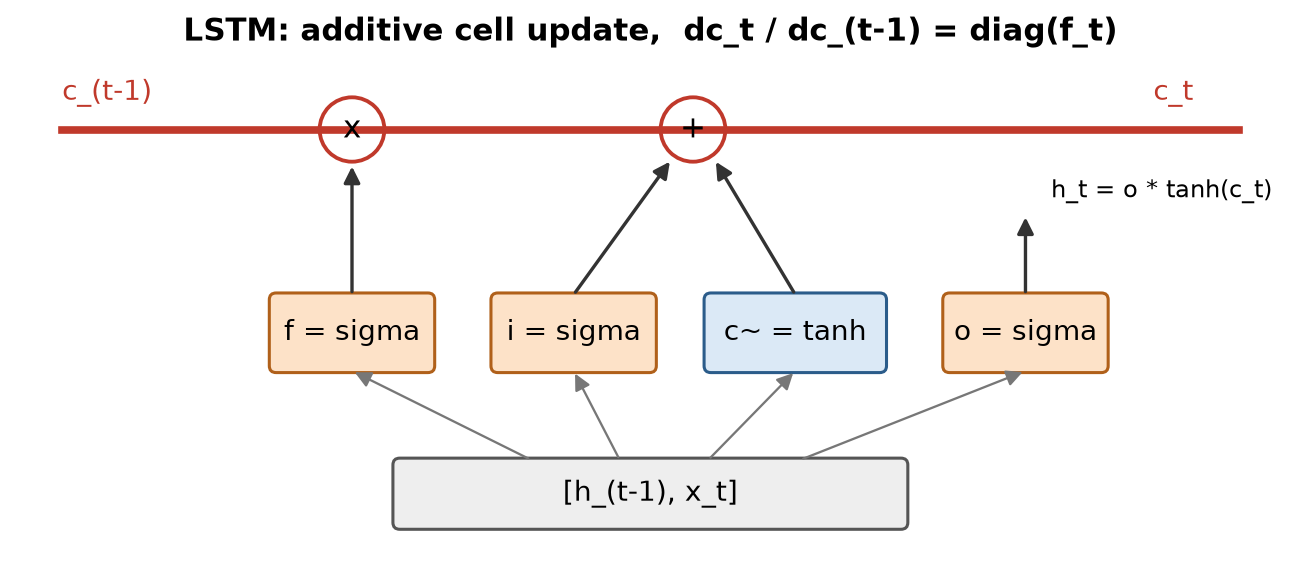

### 5.5. Температура

При генерации логиты делят на температуру $\tau$: $p_\tau \propto \exp(z/\tau)$. При $\tau \to 0$ получается жадный выбор, при $\tau \to \infty$ — равномерное распределение. Энтропия $p_\tau$ монотонно растёт с $\tau$. Кросс-энтропия на данных минимальна при $\tau = 1$ только для откалиброванной модели; положение минимума — простой тест калибровки (раздел 15.3).

# Часть II. Практикум

| Раздел | Что делаем | Связь с теорией |
|---|---|---|
| 6 | настройка, корпуса: «Анна Каренина» на русском и английском, Tiny Shakespeare | — |
| 7 | byte-level BPE с нуля, проверка $\mathrm{decode}(\mathrm{encode}(x)) = x$, сверка с `tokenizers` | раздел 3 |
| 8 | Unigram LM с нуля: EM, Viterbi, прунинг; сверка с `sentencepiece` | раздел 3 |
| 9 | сжатие и fertility для русского и английского, «налог на токены», числа | раздел 3 |
| 10 | матрица PPMI и SVD | раздел 4 |
| 11 | SGNS с нуля: ручной градиент, проверка теоремы Леви–Голдберга | раздел 4 |
| 12 | n-граммные LM: Лаплас и Kneser–Ney, perplexity и bits-per-byte | разделы 1–2 |
| 13 | градиент softmax и ручной обратный проход RNN | раздел 5 |
| 14 | затухание и взрыв градиентов в RNN | раздел 5 |
| 15 | символьные RNN и LSTM, клиппинг, температура | раздел 5 |
| 16 | сводная таблица языковых моделей | все |

## 6. Настройка и данные

Все параметры экспериментов собраны в словаре `S`. На CPU автоматически включается `FAST_DEV_RUN`: меньше слияний BPE, меньше эпох и шагов обучения. На GPU в Colab (`Runtime → Change runtime type → T4 GPU`) сети и обучение крупнее; эта ветка написана, но с сохранёнными выводами не проверялась.

In [1]:
import os, re, math, time, random, collections, urllib.request, unicodedata
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
SEED = 0
T_START = time.time()
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.grid": True, "grid.alpha": 0.3})

S = dict(
    bpe_vocab=8000,                                   # итоговый словарь BPE (256 байтов + слияния)
    uni_vocab=4000, uni_seed_size=40000, uni_max_len=12,
    w2v_min_count=10, w2v_window=5, w2v_dim=100, w2v_neg=5,
    w2v_epochs=3 if FAST_DEV_RUN else 6,
    svd_dim=100,
    ngram_max=7,
    rnn_hidden=256 if FAST_DEV_RUN else 512, rnn_seq=128, rnn_bs=32 if FAST_DEV_RUN else 64,
    rnn_steps=4000 if FAST_DEV_RUN else 10000, rnn_lr=3e-3,
)
print(f"device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}, torch {torch.__version__}")
print(S)

class Timer:
    def __enter__(self): self.t = time.time(); return self
    def __exit__(self, *a): self.s = time.time() - self.t

device=cpu, FAST_DEV_RUN=True, torch 2.14.1+cpu
{'bpe_vocab': 8000, 'uni_vocab': 4000, 'uni_seed_size': 40000, 'uni_max_len': 12, 'w2v_min_count': 10, 'w2v_window': 5, 'w2v_dim': 100, 'w2v_neg': 5, 'w2v_epochs': 3, 'svd_dim': 100, 'ngram_max': 7, 'rnn_hidden': 256, 'rnn_seq': 128, 'rnn_bs': 32, 'rnn_steps': 4000, 'rnn_lr': 0.003}


### 6.1. Корпуса

Для сравнения языков нужен один и тот же текст на двух языках: берём роман Л. Н. Толстого «Анна Каренина» в оригинале (собрание [RusLit](https://github.com/d0rj/RusLit)) и в английском переводе Констанс Гарнетт ([Project Gutenberg](https://www.gutenberg.org/ebooks/1399)). Для эмбеддингов слов (разделы 10–11) к английской «Анне Карениной» добавлен английский перевод «Войны и мира» ([Project Gutenberg](https://www.gutenberg.org/ebooks/2600)): статистике совместной встречаемости нужен корпус побольше. Для языковых моделей в разделах 12–15 используется Tiny Shakespeare — 1,1 млн символов пьес Шекспира, стандартный учебный корпус ([Karpathy, char-rnn](https://github.com/karpathy/char-rnn)).

Очистка минимальная: отрезаем служебный текст Gutenberg и комментарии к русскому изданию, склеиваем строки, разорванные переносом, и сжимаем пробелы.

In [2]:
URLS = {
    "ak_ru.txt": "https://raw.githubusercontent.com/d0rj/RusLit/main/prose/Tolstoy/%D0%90%D0%BD%D0%BD%D0%B0%20%D0%9A%D0%B0%D1%80%D0%B5%D0%BD%D0%B8%D0%BD%D0%B0.txt",
    "ak_en.txt": "https://www.gutenberg.org/cache/epub/1399/pg1399.txt",
    "wp_en.txt": "https://www.gutenberg.org/cache/epub/2600/pg2600.txt",
    "shakespeare.txt": "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
}
os.makedirs("data", exist_ok=True)
for fn, url in URLS.items():
    if not os.path.exists(f"data/{fn}"):
        urllib.request.urlretrieve(url, f"data/{fn}")

def clean(s):
    s = unicodedata.normalize("NFC", s.replace("\r", ""))
    s = re.sub(r"\n{2,}", "\0", s)                      # абзацы
    s = re.sub(r"[ \t]*\n[ \t]*", " ", s)               # переносы внутри абзаца
    s = re.sub(r"[ \t]+", " ", s).replace("\0", "\n")
    return re.sub(r"\n\s*\n+", "\n", s).strip() + "\n"

raw = open("data/ak_ru.txt", encoding="utf-8").read()
RU = clean(raw[raw.index("Все счастливые семьи"):raw.index("\nКонец\n")])
raw = open("data/ak_en.txt", encoding="utf-8").read()
EN = clean(raw[raw.index("Happy families are all alike"):raw.index("*** END OF THE PROJECT")])
raw = open("data/wp_en.txt", encoding="utf-8").read()
WP = clean(raw[raw.index("\n", raw.index("*** START")):raw.index("*** END OF THE PROJECT")])
SH = open("data/shakespeare.txt", encoding="utf-8").read()

for name, t in [("RU", RU), ("EN", EN), ("WP", WP), ("SH", SH)]:
    print(f"{name}: {len(t):>9,} символов, {len(t.encode('utf-8')):>9,} байт UTF-8, {len(t.split()):>7,} слов | {t[:70]!r}")

RU: 1,702,217 символов, 3,064,657 байт UTF-8, 280,836 слов | 'Все счастливые семьи похожи друг на друга, каждая несчастливая семья н'
EN: 1,956,582 символов, 2,000,113 байт UTF-8, 349,732 слов | 'Happy families are all alike; every unhappy family is unhappy in its o'
WP: 3,192,270 символов, 3,258,121 байт UTF-8, 563,286 слов | 'WAR AND PEACE\nBy Leo Tolstoy/Tolstoi\n Contents\n BOOK ONE: 1805\n CHAPTE'
SH: 1,115,394 символов, 1,115,394 байт UTF-8, 202,651 слов | 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpe'


Обратите внимание на соотношение байтов и символов: в UTF-8 латиница занимает 1 байт, кириллица — 2. Уже на уровне байтов русский текст «дороже» английского, и токенизатор должен это компенсировать слияниями (раздел 9).

## 7. Byte-level BPE с нуля

Алгоритм из раздела 3. Текст сначала разбивается регулярным выражением на «претокены»: слово вместе с ведущим пробелом, группа цифр, группа знаков препинания, пробелы. Слияния не пересекают границы претокенов, поэтому обучение идёт по словарю частот претокенов, а не по всему тексту. Это та же схема, что у GPT-2 ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)); наше регулярное выражение проще, но устроено так же.

Каждый претокен — последовательность байтов UTF-8 (базовый словарь из 256 символов, поэтому неизвестных символов не бывает). На каждом шаге выбирается самая частая пара соседних символов и заменяется новым символом. Чтобы не пересчитывать все пары заново, храним счётчики пар, индекс «пара → слова, где она встречается» и кучу с ленивым удалением устаревших записей.

In [3]:
import heapq
PAT = re.compile(r" ?[^\W\d_]+| ?\d+| ?(?:[^\s\w]|_)+|\s+(?!\S)|\s+|.", re.S)   # последняя ветка ловит всё остальное

def pretokenize(text):
    return PAT.findall(text)

def bpe_train(text, vocab_size, verbose=True):
    wc = collections.Counter(pretokenize(text))
    words = [list(w.encode("utf-8")) for w in wc]; freqs = list(wc.values())
    pc = collections.Counter(); where = collections.defaultdict(set)
    for i, w in enumerate(words):
        for p in zip(w, w[1:]): pc[p] += freqs[i]; where[p].add(i)
    heap = [(-c, p) for p, c in pc.items()]; heapq.heapify(heap)
    merges = []
    while len(merges) < vocab_size - 256 and heap:
        c, best = heapq.heappop(heap)
        if -c != pc.get(best, 0): continue                 # устаревшая запись кучи
        if -c < 2: break
        new = 256 + len(merges); merges.append(best); changed = set()
        for i in where.pop(best, ()):
            w, f = words[i], freqs[i]
            for p in zip(w, w[1:]): pc[p] -= f; changed.add(p)
            nw, j = [], 0
            while j < len(w):
                if j < len(w) - 1 and w[j] == best[0] and w[j + 1] == best[1]: nw.append(new); j += 2
                else: nw.append(w[j]); j += 1
            words[i] = nw
            for p in zip(nw, nw[1:]): pc[p] += f; where[p].add(i); changed.add(p)
        pc.pop(best, None)
        for p in changed:
            if pc.get(p, 0) > 0: heapq.heappush(heap, (-pc[p], p))
            else: pc.pop(p, None)
    return merges

class BPE:
    def __init__(self, merges):
        self.merges = merges
        self.rank = {p: i for i, p in enumerate(merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(merges): self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        self.cache = {}
    def truncated(self, vocab_size):                      # словарь меньшего размера = префикс списка слияний
        return BPE(self.merges[:vocab_size - 256])
    def _encode_word(self, w):
        if w in self.cache: return self.cache[w]
        ids = list(w.encode("utf-8"))
        while len(ids) > 1:                               # сливаем пару с наименьшим рангом, как при обучении
            r, k = min((self.rank.get(p, 1 << 30), k) for k, p in enumerate(zip(ids, ids[1:])))
            if r == 1 << 30: break
            new = 256 + r; out, j = [], 0
            while j < len(ids):
                if j < len(ids) - 1 and (ids[j], ids[j + 1]) == self.merges[r]: out.append(new); j += 2
                else: out.append(ids[j]); j += 1
            ids = out
        self.cache[w] = ids; return ids
    def encode(self, text):
        return [t for w in pretokenize(text) for t in self._encode_word(w)]
    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")
    def tok_str(self, i):
        return self.vocab[i].decode("utf-8", errors="backslashreplace")

BPE_TOK = {}
for lang, text in [("en", EN), ("ru", RU)]:
    with Timer() as tm: BPE_TOK[lang] = BPE(bpe_train(text, S["bpe_vocab"]))
    print(f"{lang}: {len(BPE_TOK[lang].merges)} слияний за {tm.s:.1f} с")
for lang in ["en", "ru"]:
    tk = BPE_TOK[lang]
    print(f"\n{lang}, первые 12 слияний:", " | ".join(repr(tk.tok_str(256 + i)) for i in range(12)))
    print(f"{lang}, слияния 3000-3011:", " | ".join(repr(tk.tok_str(256 + i)) for i in range(3000, 3012)))

en: 7744 слияний за 1.4 с


ru: 7744 слияний за 7.3 с

en, первые 12 слияний: ' t' | 'he' | ' a' | 'in' | ' s' | ' w' | '\\xe2\\x80' | ' the' | ' h' | 'nd' | ' o' | 're'
en, слияния 3000-3011: ' remained' | ' direct' | ' decision' | ' loss' | ' hurt' | ' broad' | ' crim' | ' merchant' | ' papa' | ' acquaintances' | ' property' | ' stream'

ru, первые 12 слияний: ' \\xd0' | 'о' | 'е' | 'а' | 'т' | 'и' | 'с' | 'н' | 'л' | 'р' | 'о\\xd0' | 'у'
ru, слияния 3000-3011: ' Оп' | 'нулись' | ' приг' | ' поддерж' | 'лаш' | 'няла' | ' Пес' | ' руков' | ' стояла' | 'ительное' | ' оправ' | 'исто'


**Что видно.** Обучение 7744 слияний (8000 минус 256 байтов) заняло 1,4 с на английском тексте и 7,3 с на русском. Первые английские слияния — частые пары букв и служебные куски: `' t'`, `'he'`, `' a'`, `'in'`; седьмым идёт `'\xe2\x80'` — первые два байта типографских кавычек и тире в UTF-8, восьмым — `' the'`. В русском первые слияния склеивают байт 0xD0 со вторым байтом кириллической буквы (`'о'`, `'е'`, `'а'`, `'т'`): BPE сначала собирает двухбайтовые символы и только потом части слов. К слиянию 3000 английский словарь состоит из целых слов (`' remained'`, `' decision'`), русский — в основном из основ и окончаний (`' поддерж'`, `'нулись'`, `'ительное'`): словоформ в русском больше, и словарь того же размера покрывает меньшую долю слов целиком.

### 7.1. Проверка обратимости и сегментации

Главный тест токенизатора — $\mathrm{decode}(\mathrm{encode}(x)) = x$ на всём корпусе и на строках, которых в обучении не было: другие алфавиты, четырёхбайтовые символы UTF-8, управляющие символы. Для byte-level BPE это должно выполняться всегда, потому что любой байт есть в базовом словаре.

In [4]:
tests = ["Привет, мир! 你好 𝄞 \t\x00 naïve café 12345.678", "x" * 50, "", " \n\n  ", "Ё ё й Й — «ёлки»"]
for lang, text in [("en", EN), ("ru", RU)]:
    tk = BPE_TOK[lang]
    with Timer() as tm: ids = tk.encode(text)
    ok_corpus = tk.decode(ids) == text
    ok_tests = all(tk.decode(tk.encode(s)) == s for s in tests)
    print(f"{lang}: корпус {len(text):,} символов -> {len(ids):,} токенов за {tm.s:.1f} с; "
          f"decode(encode(x)) == x: корпус {ok_corpus}, тестовые строки {ok_tests}")

def show_seg(tk, s):
    return " ".join("[" + tk.tok_str(i).replace(" ", "_") + "]" for i in tk.encode(s))
for lang, s in [("en", "Happy families are all alike; unhappiness is individual."),
                ("ru", "Все счастливые семьи похожи друг на друга; несчастливость индивидуальна."),
                ("en", "Levin was mowing"), ("ru", "Левин косил траву")]:
    print(f"{lang}: {show_seg(BPE_TOK[lang], s)}")

en: корпус 1,956,582 символов -> 464,493 токенов за 0.4 с; decode(encode(x)) == x: корпус True, тестовые строки True


ru: корпус 1,702,217 символов -> 442,071 токенов за 1.8 с; decode(encode(x)) == x: корпус True, тестовые строки True
en: [H] [app] [y] [_families] [_are] [_all] [_alike] [;] [_unhappiness] [_is] [_individual] [.]
ru: [Все] [_счастлив] [ые] [_семьи] [_похож] [и] [_друг] [_на] [_друга] [;] [_несчастлив] [ость] [_ин] [див] [ид] [у] [аль] [на] [.]
en: [Levin] [_was] [_mowing]
ru: [Левин] [_кос] [ил] [_траву]


**Что видно.** Равенство $\mathrm{decode}(\mathrm{encode}(x)) = x$ выполняется на всём корпусе и на тестовых строках с иероглифами, четырёхбайтовым символом 𝄞, нулевым байтом и пустой строкой: byte-level BPE обратим по построению. Английский корпус из 1,96 млн символов превращается в 464 тыс. токенов, русский из 1,70 млн символов — в 442 тыс. Английская фраза почти целиком состоит из целых слов, русская распадается на основы и окончания («_счастлив|ые», «_несчастлив|ость»), а редкое «индивидуальна» — на шесть кусков.

### 7.2. Сверка с библиотекой `tokenizers`

Обучим BPE из библиотеки Hugging Face `tokenizers` с тем же разбиением на претокены и тем же размером словаря. Алгоритм тот же, поэтому списки слияний должны почти совпасть; расхождения возможны только из-за правил разрешения равных частот.

In [5]:
try:
    from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, Regex
    def hf_bpe(text, vocab_size):
        tok = Tokenizer(models.BPE())
        tok.pre_tokenizer = pre_tokenizers.Sequence([
            pre_tokenizers.Split(Regex(PAT.pattern), behavior="isolated"),
            pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=False)])
        tok.decoder = decoders.ByteLevel()
        tr = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2, show_progress=False,
                                 initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), special_tokens=[])
        tok.train_from_iterator([text], trainer=tr)
        return tok
    def bytes_to_unicode():                                   # отображение байтов в символы из GPT-2
        bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256)); cs = bs[:]; n = 0
        for b in range(256):
            if b not in bs: bs.append(b); cs.append(256 + n); n += 1
        return {chr(c): b for b, c in zip(bs, cs)}
    U2B = bytes_to_unicode()
    HF_BPE = {}
    for lang, text in [("en", EN), ("ru", RU)]:
        with Timer() as tm: HF_BPE[lang] = hf_bpe(text, S["bpe_vocab"])
        n_hf = len(HF_BPE[lang].encode(text).ids); n_our = len(BPE_TOK[lang].encode(text))
        hf_bytes = {bytes(U2B[ch] for ch in t) for t in HF_BPE[lang].get_vocab()}
        our_bytes = set(BPE_TOK[lang].vocab.values())
        print(f"{lang}: tokenizers {tm.s:.1f} с, словарь {len(hf_bytes)}; токенов на корпусе: наш {n_our:,}, "
              f"tokenizers {n_hf:,} (разница {100 * (n_our - n_hf) / n_hf:+.2f}%); "
              f"общих токенов {len(hf_bytes & our_bytes) / len(our_bytes):.3f}")
except ImportError as e:
    print("tokenizers не установлен:", e)

en: tokenizers 0.9 с, словарь 8000; токенов на корпусе: наш 464,493, tokenizers 464,493 (разница +0.00%); общих токенов 1.000


ru: tokenizers 1.5 с, словарь 8000; токенов на корпусе: наш 442,071, tokenizers 442,071 (разница +0.00%); общих токенов 1.000


**Что видно.** Библиотечный BPE с тем же претокенизатором и размером словаря даёт на обоих корпусах ровно столько же токенов, и словари совпадают полностью (доля общих токенов 1,000). Наша реализация воспроизводит алгоритм точно; отличается только время: 1,4 с против 0,9 с на английском, 7,3 с против 1,5 с на русском.

## 8. Unigram LM с нуля

Unigram-токенизатор устроен наоборот по сравнению с BPE: он начинает с большого словаря и удаляет из него лишнее ([Kudo, 2018](https://arxiv.org/abs/1804.10959)). Модель: каждый подслов $u$ имеет вероятность $p(u)$, сегментация $\mathbf{u} = (u_1, \dots, u_k)$ слова $x$ имеет вероятность $\prod_i p(u_i)$, а вероятность слова — сумма по всем сегментациям. Обучение — EM-алгоритм.

1. Начальный словарь: все символы и самые частые подстроки длиной до `uni_max_len`.
2. E-шаг: прямой и обратный проходы по решётке сегментаций каждого слова дают ожидаемое число использований каждого подслова.
3. M-шаг: $p(u) \propto$ ожидаемое число использований.
4. Прунинг: для каждого подслова оцениваем, насколько вырастет потеря (минус логарифм правдоподобия корпуса), если его удалить и заменить лучшей сегментацией из оставшихся. Оставляем 75% самых полезных, символы не удаляем никогда.
5. Повторяем 2–4, пока словарь не сократится до нужного размера; кодирование — сегментация Витерби.

In [6]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log1p(math.exp(-abs(a - b)))

class Unigram:
    def __init__(self, logp, max_len):
        self.logp, self.max_len = logp, max_len
    def viterbi(self, w, logp=None):
        logp = logp or self.logp; L = len(w)
        best = [0.0] + [-math.inf] * L; back = [0] * (L + 1)
        for i in range(1, L + 1):
            for j in range(max(0, i - self.max_len), i):
                lp = logp.get(w[j:i])
                if lp is not None and best[j] + lp > best[i]: best[i], back[i] = best[j] + lp, j
        out, i = [], L
        while i > 0: out.append(w[back[i]:i]); i = back[i]
        return out[::-1], best[L]
    def encode(self, text):
        return [u for w in pretokenize(text) for u in self.viterbi(w)[0]]
    def sample(self, w, alpha=1.0, rng=random):
        """Сэмплирование сегментации из p(u|x)^alpha: прямой проход, затем обратный сэмплинг."""
        L = len(w); a = [0.0] + [-math.inf] * L
        for i in range(1, L + 1):
            for j in range(max(0, i - self.max_len), i):
                lp = self.logp.get(w[j:i])
                if lp is not None: a[i] = logsumexp2(a[i], a[j] + alpha * lp)
        out, i = [], L
        while i > 0:
            cand = [(j, a[j] + alpha * self.logp[w[j:i]]) for j in range(max(0, i - self.max_len), i) if w[j:i] in self.logp]
            m = max(c for _, c in cand); r = rng.random() * sum(math.exp(c - m) for _, c in cand)
            for j, c in cand:
                r -= math.exp(c - m)
                if r <= 0: break
            out.append(w[j:i]); i = j
        return out[::-1]

def unigram_train(text, vocab_size, seed_size, max_len, shrink=0.75, em_iters=2, verbose=True):
    wc = collections.Counter(pretokenize(text)); words = list(wc.items())
    sub = collections.Counter()
    for w, f in words:
        for i in range(len(w)):
            for j in range(i + 1, min(len(w), i + max_len) + 1): sub[w[i:j]] += f
    chars = {u for u in sub if len(u) == 1}
    seed = dict(sub.most_common(seed_size)); seed.update({c: sub[c] for c in chars})
    tot = sum(seed.values()); logp = {u: math.log(c / tot) for u, c in seed.items()}
    model = Unigram(logp, max_len); hist = []
    while True:
        for _ in range(em_iters):                              # EM
            cnt = collections.defaultdict(float); ll = 0.0
            for w, f in words:
                L = len(w); a = [0.0] + [-math.inf] * L; b = [-math.inf] * L + [0.0]
                for i in range(1, L + 1):
                    for j in range(max(0, i - max_len), i):
                        lp = logp.get(w[j:i])
                        if lp is not None: a[i] = logsumexp2(a[i], a[j] + lp)
                for j in range(L - 1, -1, -1):
                    for i in range(j + 1, min(L, j + max_len) + 1):
                        lp = logp.get(w[j:i])
                        if lp is not None: b[j] = logsumexp2(b[j], lp + b[i])
                Z = a[L]; ll += f * Z
                for i in range(1, L + 1):
                    for j in range(max(0, i - max_len), i):
                        lp = logp.get(w[j:i])
                        if lp is not None: cnt[w[j:i]] += f * math.exp(a[j] + lp + b[i] - Z)
            tot = sum(cnt.values())
            logp = {u: math.log(c / tot) for u, c in cnt.items() if c > 0}
            for c in chars: logp.setdefault(c, math.log(1e-3 / tot))
            model.logp = logp
        hist.append((len(logp), -ll / sum(f for _, f in words)))
        if verbose: print(f"  словарь {len(logp):6d}, -log p на претокен {hist[-1][1]:.3f}")
        if len(logp) <= vocab_size: break
        # прунинг: потеря от удаления u ~ freq_viterbi(u) * (log p(u) - log p(лучшая замена без u))
        vit = collections.Counter()
        for w, f in words:
            for u in model.viterbi(w)[0]: vit[u] += f
        loss = {}
        for u, lp in list(logp.items()):
            if len(u) == 1: continue
            if vit[u] == 0: loss[u] = 0.0; continue
            del logp[u]; _, lp_alt = model.viterbi(u, logp); logp[u] = lp   # лучшая замена без u
            loss[u] = vit[u] * (lp - lp_alt)
        keep_n = max(vocab_size, int(len(logp) * shrink)) - len(chars)
        keep = set(sorted(loss, key=loss.get, reverse=True)[:keep_n]) | chars
        logp = {u: logp[u] for u in keep}; model.logp = logp
    return model, hist

UNI_TOK = {}
for lang, text in [("en", EN), ("ru", RU)]:
    print(lang)
    with Timer() as tm: UNI_TOK[lang], _ = unigram_train(text, S["uni_vocab"], S["uni_seed_size"], S["uni_max_len"])
    print(f"{lang}: обучение {tm.s:.0f} с, итоговый словарь {len(UNI_TOK[lang].logp)}")

en


  словарь  40012, -log p на претокен 6.931


  словарь  30009, -log p на претокен 6.781


  словарь  22506, -log p на претокен 6.778


  словарь  16879, -log p на претокен 6.777


...

  словарь   9499, -log p на претокен 8.444


  словарь   7124, -log p на претокен 8.543


  словарь   5343, -log p на претокен 8.720


  словарь   4007, -log p на претокен 8.965


  словарь   4000, -log p на претокен 8.965
ru: обучение 34 с, итоговый словарь 4000


**Что видно.** EM с прунингом сокращает затравочный словарь примерно с 40 тыс. подстрок до 4000. Пока словарь больше примерно 9,5 тыс., средняя $-\log p$ на претокен почти не меняется: удаляются избыточные подстроки. Дальше потеря растёт: у английского с 6,777 до 7,044, у русского с 8,400 до 8,965. Русскому при том же словаре нужно больше бит на слово, потому что словоформ больше. Обучение заняло 12 с и 34 с.

### 8.1. Сегментации, сэмплирование и сверка с `sentencepiece`

Unigram даёт не одну сегментацию, а распределение над ними. Kudo предложил на обучении сэмплировать сегментацию из $p(\mathbf{u} \mid x)^\alpha$ (subword regularization): модель видит одно слово в разных разбиениях и становится устойчивее ([Kudo, 2018](https://arxiv.org/abs/1804.10959)). Затем сравниваем с реализацией Unigram из `sentencepiece` ([Kudo & Richardson, 2018](https://arxiv.org/abs/1808.06226)) при том же размере словаря.

In [7]:
for lang, s in [("en", "Happy families are all alike; unhappiness is individual."),
                ("ru", "Все счастливые семьи похожи друг на друга; несчастливость индивидуальна.")]:
    print(f"{lang} Viterbi: " + " ".join("[" + u.replace(" ", "_") + "]" for u in UNI_TOK[lang].encode(s)))
rng = random.Random(0)
for alpha in [1.0, 0.3, 0.1]:
    for lang, w in [("en", " unhappiness"), ("ru", " несчастливая")]:
        samples = collections.Counter("|".join(UNI_TOK[lang].sample(w, alpha, rng)) for _ in range(200))
        top = ", ".join(f"{seg} ({c})" for seg, c in samples.most_common(4))
        print(f"alpha={alpha}: {lang} {w!r}: {len(samples)} различных сегментаций из 200; частые: {top}")

for lang, text in [("en", EN), ("ru", RU)]:
    ids = UNI_TOK[lang].encode(text)
    print(f"{lang}: Unigram-{S['uni_vocab']}: {len(ids):,} токенов; обратимость {''.join(ids) == text}")

try:
    import sentencepiece as spm
    for lang, text in [("en", EN), ("ru", RU)]:
        open(f"data/sp_{lang}.txt", "w", encoding="utf-8").write(text)
        with Timer() as tm:
            spm.SentencePieceTrainer.train(input=f"data/sp_{lang}.txt", model_prefix=f"data/sp_{lang}", vocab_size=S["uni_vocab"],
                model_type="unigram", character_coverage=1.0, max_sentencepiece_length=S["uni_max_len"],
                split_digits=False, byte_fallback=False, add_dummy_prefix=False, minloglevel=2,
                max_sentence_length=1 << 20, train_extremely_large_corpus=False)
        sp = spm.SentencePieceProcessor(model_file=f"data/sp_{lang}.model")
        n_sp = sum(len(sp.encode(line)) for line in text.split("\n"))
        sp_vocab = {sp.id_to_piece(i).replace("▁", " ") for i in range(sp.get_piece_size())}
        ours = set(UNI_TOK[lang].logp)
        n_our = len(UNI_TOK[lang].encode(text))
        print(f"{lang}: sentencepiece {tm.s:.1f} с; токенов: наш {n_our:,}, sentencepiece {n_sp:,} "
              f"(разница {100 * (n_our - n_sp) / n_sp:+.1f}%); общих подслов {len(ours & sp_vocab) / len(ours):.2f}")
except ImportError as e:
    print("sentencepiece не установлен:", e)

en Viterbi: [Happ] [y] [_families] [_are] [_all] [_a] [like] [;] [_unhappiness] [_is] [_individual] [.]
ru Viterbi: [Все] [_счастлив] [ые] [_семь] [и] [_похож] [и] [_друг] [_на] [_друга] [;] [_несчастлив] [ость] [_и] [нд] [и] [вид] [у] [а] [ль] [на] [.]
alpha=1.0: en ' unhappiness': 1 различных сегментаций из 200; частые:  unhappiness (200)
alpha=1.0: ru ' несчастливая': 2 различных сегментаций из 200; частые:  несчастлив|ая (184),  несчастлив|а|я (16)
alpha=0.3: en ' unhappiness': 2 различных сегментаций из 200; частые:  unhappiness (199),  un|ha|p|p|i|ness (1)
alpha=0.3: ru ' несчастливая': 3 различных сегментаций из 200; частые:  несчастлив|ая (135),  несчастлив|а|я (64),  |не|с|ча|ст|л|ивая (1)
alpha=0.1: en ' unhappiness': 48 различных сегментаций из 200; частые:  unhappiness (90),  un|ha|p|p|iness (10),  |un|h|ap|p|iness (8),  un|h|ap|p|iness (5)
alpha=0.1: ru ' несчастливая': 83 различных сегментаций из 200; частые:  несчастлив|ая (30),  несчастлив|а|я (22),  не|с|ч|а|с|т|лив|ая

en: Unigram-4000: 495,301 токенов; обратимость True


ru: Unigram-4000: 496,278 токенов; обратимость True


en: sentencepiece 1.9 с; токенов: наш 495,301, sentencepiece 491,360 (разница +0.8%); общих подслов 0.80


ru: sentencepiece 3.9 с; токенов: наш 496,278, sentencepiece 495,934 (разница +0.1%); общих подслов 0.67


**Что видно.** Сегментации Витерби у Unigram и BPE похожи, но не совпадают: Unigram режет «Happy» как «Happ|y», «alike» как «_a|like», а русское «индивидуальна» дробит ещё мельче. Сэмплирование показывает, как $\alpha$ управляет разнообразием. При $\alpha = 1$ почти всегда выдаётся лучшая сегментация (1 и 2 варианта из 200). При $\alpha = 0{,}1$ получается 48 и 83 различных сегментации, и самая вероятная встречается только в 90 и 30 случаях из 200 — это и есть регуляризация subword sampling. По сравнению с `sentencepiece` число токенов отличается на 0,8 % для английского и на 0,1 % для русского, но общих подслов лишь 80 % и 67 %: у EM много почти равноценных решений, и детали затравки и прунинга решают, какие подслова останутся.

## 9. Сжатие, fertility и «налог на токены»

Метрики токенизатора на корпусе:

- байтов на токен — степень сжатия (больше — короче последовательность для модели);
- fertility — среднее число токенов на слово (меньше — слова реже дробятся);
- доля словаря, использованная меньше 10 раз, — сколько «мёртвых» токенов, для которых эмбеддинг почти не обучится.

Так как список слияний BPE упорядочен, словарь меньшего размера — просто префикс этого списка, и одно обучение даёт все размеры сразу.

lang  vocab    tokens bytes/tok fertility  rare<10


en      512   892,200      2.24      2.55    0.348


en     1000   689,723      2.90      1.97    0.190


en     2000   576,528      3.47      1.65    0.137


en     4000   506,076      3.95      1.45    0.159


...

ru      512   916,951      3.34      3.27    0.309


ru     1000   702,164      4.36      2.50    0.177


ru     2000   579,867      5.29      2.06    0.112


ru     4000   498,250      6.15      1.77    0.100


ru     8000   442,071      6.93      1.57    0.220


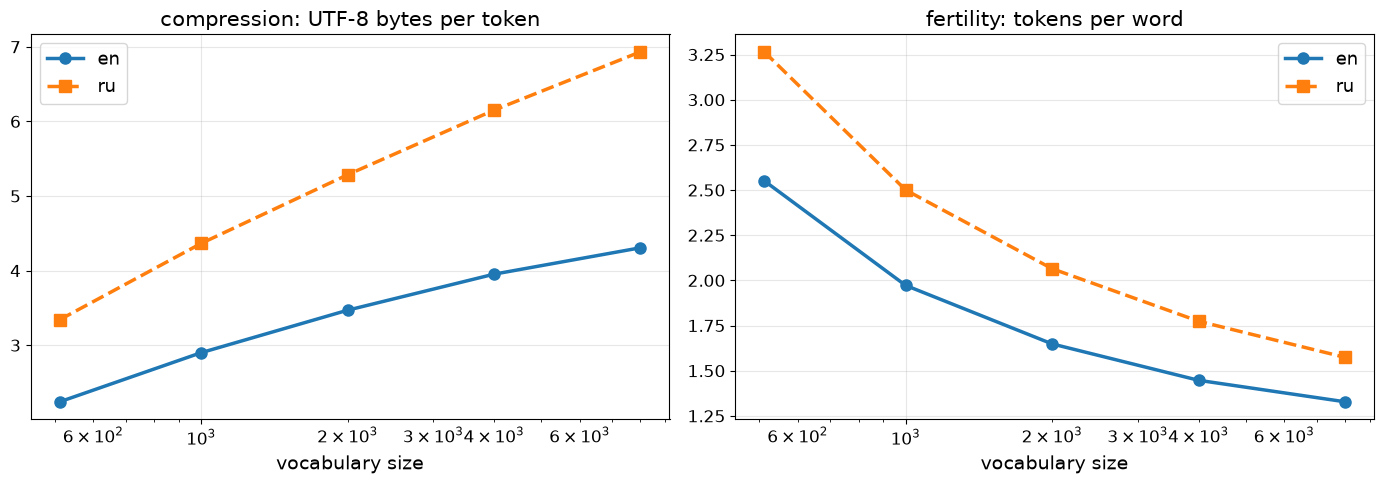

In [8]:
SIZES = [512, 1000, 2000, 4000, 8000]
def tok_stats(encode_fn, text, vocab_size=None):
    ids = encode_fn(text); n_words = len(text.split())
    st = dict(tokens=len(ids), bpt=len(text.encode("utf-8")) / len(ids), fert=len(ids) / n_words)
    if vocab_size:
        c = collections.Counter(ids); st["rare"] = sum(1 for i in range(vocab_size) if c[i] < 10) / vocab_size
    return st

STATS = {}
print(f"{'lang':4s} {'vocab':>6s} {'tokens':>9s} {'bytes/tok':>9s} {'fertility':>9s} {'rare<10':>8s}")
for lang, text in [("en", EN), ("ru", RU)]:
    for vs in SIZES:
        tk = BPE_TOK[lang].truncated(vs)
        st = STATS[(lang, vs)] = tok_stats(tk.encode, text, vs)
        print(f"{lang:4s} {vs:6d} {st['tokens']:9,d} {st['bpt']:9.2f} {st['fert']:9.2f} {st['rare']:8.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for lang, mk in [("en", "o-"), ("ru", "s--")]:
    ax[0].plot(SIZES, [STATS[(lang, vs)]["bpt"] for vs in SIZES], mk, lw=2.5, ms=8, label=lang)
    ax[1].plot(SIZES, [STATS[(lang, vs)]["fert"] for vs in SIZES], mk, lw=2.5, ms=8, label=lang)
for a, t in zip(ax, ["compression: UTF-8 bytes per token", "fertility: tokens per word"]):
    a.set_xscale("log"); a.set_xlabel("vocabulary size", fontsize=14); a.set_title(t, fontsize=15)
    a.legend(fontsize=13); a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

**Что видно.** С ростом словаря от 512 до 8000 сжатие растёт у обоих языков, у русского сильнее: от 3,34 до 6,93 байта на токен против 2,24–4,31 у английского. Сравнение в байтах здесь нечестное: кириллическая буква занимает 2 байта. По fertility (токенов на слово) русский хуже при каждом размере словаря, например 1,57 против 1,33 при 8000. Столбец rare<10 — доля токенов словаря, встретившихся в корпусе меньше 10 раз. При словаре 8000 у английского таких почти половина (0,488): новые слияния обслуживают единичные слова и почти ничего не дают.

### 9.1. Один и тот же роман: чей токенизатор?

Теперь сравним длину одного и того же текста на двух языках при разных токенизаторах: английский BPE, применённый к русскому тексту; общий BPE, обученный на смеси языков; и токенизаторы реальных моделей — GPT-2 (обучен в основном на английском веб-тексте) и Qwen2.5 (многоязычный). Отношение «токенов на русском / токенов на английском» для параллельного текста — и есть «налог на токены»: при одинаковом содержании русский пользователь платит за больше токенов, получает меньший эффективный контекст и более медленную генерацию ([Petrov et al., 2023](https://arxiv.org/abs/2305.15425)).

In [9]:
with Timer() as tm: BPE_TOK["joint"] = BPE(bpe_train(RU + EN, S["bpe_vocab"]))
print(f"общий BPE-{S['bpe_vocab']} на RU+EN: {tm.s:.1f} с")
rows = [("BPE-8k (en) на каждом", BPE_TOK["en"].encode),
        ("BPE-8k (ru) на каждом", BPE_TOK["ru"].encode),
        ("BPE-8k общий RU+EN", BPE_TOK["joint"].encode)]
HF = {}
try:
    from transformers import AutoTokenizer
    for name in ["gpt2", "Qwen/Qwen2.5-0.5B"]:
        hf = HF[name] = AutoTokenizer.from_pretrained(name)
        rows.append((f"{name} ({len(hf)} токенов)", lambda t, hf=hf: hf(t, add_special_tokens=False).input_ids))
except Exception as e:
    print("токенизаторы моделей недоступны:", type(e).__name__, str(e)[:100])
TAX = {}
print(f"\n{'токенизатор':40s} {'EN tokens':>10s} {'RU tokens':>10s} {'RU/EN':>6s} {'fert EN':>8s} {'fert RU':>8s}")
for name, fn in rows:
    e, r = tok_stats(fn, EN), tok_stats(fn, RU)
    TAX[name] = r["tokens"] / e["tokens"]
    print(f"{name:40s} {e['tokens']:10,d} {r['tokens']:10,d} {TAX[name]:6.2f} {e['fert']:8.2f} {r['fert']:8.2f}")

общий BPE-8000 на RU+EN: 9.1 с



токенизатор                               EN tokens  RU tokens  RU/EN  fert EN  fert RU


BPE-8k (en) на каждом                       464,493  3,048,752   6.56     1.33    10.86


BPE-8k (ru) на каждом                     1,367,132    442,071   0.32     3.91     1.57


BPE-8k общий RU+EN                          508,329    487,314   0.96     1.45     1.74


gpt2 (50257 токенов)                        498,254  1,820,854   3.65     1.42     6.48


Qwen/Qwen2.5-0.5B (151665 токенов)          453,833    614,779   1.35     1.30     2.19


**Что видно.** Налог на токены — свойство токенизатора, а не языка. BPE, обученный на английском, кодирует русский роман в 6,56 раза большим числом токенов (10,9 токена на слово — почти побайтово). BPE, обученный на русском, наоборот, втрое хуже кодирует английский текст (отношение 0,32). Токенизатор GPT-2 обучен в основном на английском, и русская «Анна Каренина» стоит в нём в 3,65 раза больше токенов, чем английская. Многоязычный Qwen2.5 со словарём 151 тыс. сокращает разрыв до 1,35. Общий BPE-8000 на смеси двух романов даёт 0,96: при равных объёмах данных языки делят словарь почти поровну.

### 9.2. Числа

Токенизация чисел определяет, «видит» ли модель разряды. Регулярное выражение GPT-2 объединяет цифры в одну группу, и BPE режет её по частым подстрокам, которые не совпадают с разрядами. Поэтому одинаковые по длине числа сегментируются по-разному, а соседние числа — несогласованно. Некоторые современные модели разбивают числа на отдельные цифры; в LLaMA это сделано явно ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)). Проверим, как это устроено у Qwen2.5.

In [10]:
nums = ["7", "42", "1873", "1874", "18741", "123456789", "3.14159", "12345 + 67890 = 80235"]
def seg(name, s):
    if name == "ours": return " ".join("[" + BPE_TOK["en"].tok_str(i) + "]" for i in BPE_TOK["en"].encode(s))
    hf = HF[name]; return " ".join("[" + hf.decode([i]) + "]" for i in hf(s, add_special_tokens=False).input_ids)
for s in nums:
    print(f"{s!r}")
    for name in ["ours"] + list(HF):
        print(f"    {name:20s} {seg(name, s)}")

'7'
    ours                 [7]
    gpt2                 [7]
    Qwen/Qwen2.5-0.5B    [7]
'42'
    ours                 [4] [2]
    gpt2                 [42]
    Qwen/Qwen2.5-0.5B    [4] [2]
'1873'
    ours                 [1] [8] [7] [3]
    gpt2                 [18] [73]
    Qwen/Qwen2.5-0.5B    [1] [8] [7] [3]
'1874'
    ours                 [1] [8] [7] [4]
    gpt2                 [18] [74]
    Qwen/Qwen2.5-0.5B    [1] [8] [7] [4]
'18741'
    ours                 [1] [8] [7] [4] [1]
    gpt2                 [187] [41]
    Qwen/Qwen2.5-0.5B    [1] [8] [7] [4] [1]
'123456789'
    ours                 [1] [2] [3] [4] [5] [6] [7] [8] [9]
    gpt2                 [123] [45] [67] [89]
    Qwen/Qwen2.5-0.5B    [1] [2] [3] [4] [5] [6] [7] [8] [9]
'3.14159'
    ours                 [3] [.] [1] [4] [1] [5] [9]
    gpt2                 [3] [.] [14] [159]
    Qwen/Qwen2.5-0.5B    [3] [.] [1] [4] [1] [5] [9]
'12345 + 67890 = 80235'
    ours                 [1] [2] [3] [4] [5] [ ] [+] [ 6] [7] 

**Что видно.** Наш претокенизатор и Qwen2.5 разбивают числа на отдельные цифры, как в LLaMA. GPT-2 режет числа на куски из одной–трёх цифр, и разбиение зависит от частот в обучающих данных: «1873» → «18|73», «18741» → «187|41». В примере сложения слагаемые и сумма разрезаны по-разному («123|45», «6|78|90», «80|235»), и модели приходится учить арифметику на несогласованных разрядах.

## 10. Матрица PPMI и SVD

Корпус для эмбеддингов — английские переводы «Анны Карениной» и «Войны и мира», приведённые к нижнему регистру, очищенные от знаков ударения и разбитые на слова. Словарь — слова, встретившиеся не меньше `w2v_min_count` раз. Контекст слова — соседи в окне $\pm$`w2v_window` (без весов по расстоянию, чтобы матрица совпадала с тем, что видит SGNS в разделе 11).

PPMI вычисляется со сглаживанием распределения контекстов $P_\alpha(c) \propto \#c^{0.75}$: без него PMI завышено для редких контекстов. Этот приём перенесён из word2vec в счётные методы Levy, Goldberg и Dagan ([Levy et al., 2015](https://aclanthology.org/Q15-1016/)). Эмбеддинги — усечённое SVD: $W = U_d \Sigma_d^{1/2}$.

In [11]:
import scipy.sparse as sp, scipy.sparse.linalg as spla
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
import unicodedata
def strip_accents(t):   # в переводах встречаются ударения: «Pávlovna» -> «pavlovna»
    return "".join(ch for ch in unicodedata.normalize("NFKD", t) if not unicodedata.combining(ch))
corpus_words = WORD_RE.findall(strip_accents((EN + "\n" + WP).lower()).replace("\u2019", "'"))
wcount = collections.Counter(corpus_words)
VOCAB = [w for w, c in wcount.most_common() if c >= S["w2v_min_count"]]
W2I = {w: i for i, w in enumerate(VOCAB)}; V = len(VOCAB)
ids = np.array([W2I.get(w, -1) for w in corpus_words]); ids = ids[ids >= 0]   # редкие слова выбрасываем
print(f"слов в корпусе {len(corpus_words):,}, после фильтра {len(ids):,}; словарь V = {V:,}")

# матрица совместной встречаемости в окне +-window
win = S["w2v_window"]; rows, cols = [], []
for d in range(1, win + 1):
    rows += [ids[:-d], ids[d:]]; cols += [ids[d:], ids[:-d]]
rows, cols = np.concatenate(rows), np.concatenate(cols)
C = sp.coo_matrix((np.ones(len(rows), dtype=np.float64), (rows, cols)), shape=(V, V)).tocsr()
C.sum_duplicates()
n_pairs = C.sum(); nw = np.asarray(C.sum(1)).ravel(); nc = np.asarray(C.sum(0)).ravel()
pc_alpha = nc ** 0.75 / (nc ** 0.75).sum()
print(f"пар (w, c): {int(n_pairs):,}; ненулевых ячеек {C.nnz:,} ({C.nnz / V**2:.1%} матрицы)")

def pmi_matrix(C, shift=0.0, positive=True):
    C = C.tocoo()
    pmi = np.log(C.data * 1.0) - np.log(nw[C.row]) - np.log(pc_alpha[C.col]) - shift
    keep = pmi > 0 if positive else np.ones_like(pmi, bool)
    return sp.csr_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape)

PPMI = pmi_matrix(C)
with Timer() as tm:
    U, sig, Vt = spla.svds(PPMI, k=S["svd_dim"]); order = np.argsort(-sig); U, sig = U[:, order], sig[order]
EMB_SVD = U * np.sqrt(sig)
print(f"SVD ранга {S['svd_dim']}: {tm.s:.1f} с; доля квадрата нормы PPMI в первых {S['svd_dim']} компонентах: "
      f"{(sig**2).sum() / (PPMI.multiply(PPMI)).sum():.3f}")

def neighbors(E, word, k=8):
    En = E / np.linalg.norm(E, axis=1, keepdims=True); i = W2I[word]
    sims = En @ En[i]; sims[i] = -1
    return [VOCAB[j] for j in np.argsort(-sims)[:k]]
PROBE = ["anna", "levin", "horse", "love", "moscow", "happy", "went", "soldiers", "tea", "three"]
for w in PROBE:
    print(f"{w:9s} -> {', '.join(neighbors(EMB_SVD, w))}")

слов в корпусе 918,352, после фильтра 875,276; словарь V = 5,645


пар (w, c): 8,752,730; ненулевых ячеек 1,629,459 (5.1% матрицы)


SVD ранга 100: 1.8 с; доля квадрата нормы PPMI в первых 100 компонентах: 0.178
anna      -> pavlovna, vronsky, mikhaylovna, dolly, alexandrovitch, husband, alexey, betsy
levin     -> arkadyevitch, stepan, answered, konstantin, kitty, ivanovitch, sergey, vronsky
horse     -> rode, mounted, bay, chestnut, shaft, horses, galloping, gallop
love      -> happiness, loving, heart, loved, bliss, hope, soul, my
moscow    -> town, city, inhabitants, army, smolensk, abandonment, vilna, from
happy     -> glad, smile, am, radiant, shy, felt, beaming, cheerful
went      -> room, into, drawing, out, came, got, door, tiptoe
soldiers  -> officers, were, among, militiamen, ranks, carts, crowd, muskets
tea       -> samovar, coffee, cup, drinking, dinner, supper, bread, wine
three     -> two, four, five, six, hundred, years, ten, hours


**Что видно.** После фильтра по частоте остаётся словарь из 5645 слов и 8,75 млн пар (слово, контекст), матрица заполнена на 5,1 %. Первые 100 сингулярных компонент несут лишь 17,8 % квадрата нормы PPMI, но соседи уже осмысленны: tea → samovar, coffee, cup; three → two, four, five; horse → rode, mounted, chestnut. Соседи имён тематические (anna → pavlovna, vronsky; levin → kitty, konstantin): окно $\pm 5$ слов отражает и то, кто с кем встречается в тексте, а не только взаимозаменяемость слов.

## 11. Skip-gram с negative sampling с нуля

Обучаем SGNS на тех же парах (слово, контекст), из которых построена матрица PPMI: окно $\pm 5$ без случайного сокращения и без прореживания частых слов. Так результат можно сравнить с теорией Levy–Goldberg без поправок. Для каждой положительной пары берём $k$ = `w2v_neg` отрицательных контекстов из $P_\alpha(c) \propto \#c^{0.75}$ ([Mikolov et al., 2013](https://arxiv.org/abs/1310.4546)).

Функция потерь на одну пару и её градиенты (вывод — в разделе 4.3):

$
\ell = -\log\sigma(w^\top c) - \sum_{i=1}^{k}\log\sigma(-w^\top n_i),
$
$
\frac{\partial \ell}{\partial w} = (\sigma(w^\top c) - 1)\,c + \sum_i \sigma(w^\top n_i)\,n_i,\qquad
\frac{\partial \ell}{\partial c} = (\sigma(w^\top c) - 1)\,w,\qquad
\frac{\partial \ell}{\partial n_i} = \sigma(w^\top n_i)\,w.
$

Обновление делаем вручную, без autograd, как в исходном word2vec. Сначала сверяем ручной градиент с autograd и с конечными разностями.

### 11.1. Проверка градиента

In [12]:
def sgns_loss_and_grads(w, c, n):
    """w, c: (B, d); n: (B, k, d). Возвращает сумму потерь и градиенты по w, c, n."""
    sp_ = torch.sigmoid((w * c).sum(-1))                     # sigma(w.c), (B,)
    sn_ = torch.sigmoid(torch.einsum("bd,bkd->bk", w, n))    # sigma(w.n_i), (B, k)
    loss = -(torch.log(sp_) + torch.log(1 - sn_).sum(-1)).sum()
    gw = (sp_ - 1)[:, None] * c + torch.einsum("bk,bkd->bd", sn_, n)
    gc = (sp_ - 1)[:, None] * w
    gn = sn_[..., None] * w[:, None, :]
    return loss, gw, gc, gn

g = torch.Generator().manual_seed(0)
w = torch.randn(7, 10, dtype=torch.float64, generator=g, requires_grad=True)
c = torch.randn(7, 10, dtype=torch.float64, generator=g, requires_grad=True)
n = torch.randn(7, 5, 10, dtype=torch.float64, generator=g, requires_grad=True)
loss, gw, gc, gn = sgns_loss_and_grads(w, c, n)
loss.backward()
for name, man, auto in [("w", gw, w.grad), ("c", gc, c.grad), ("n", gn, n.grad)]:
    print(f"d loss / d {name}: max |ручной - autograd| = {(man - auto).abs().max().item():.2e}")
eps = 1e-6
with torch.no_grad():
    w2 = w.detach().clone(); w2[3, 4] += eps; lp = sgns_loss_and_grads(w2, c, n)[0]
    w2[3, 4] -= 2 * eps; lm = sgns_loss_and_grads(w2, c, n)[0]
print(f"конечная разность по w[3,4]: {((lp - lm) / (2 * eps)).item():.8f}, ручной градиент: {gw[3, 4].item():.8f}")

d loss / d w: max |ручной - autograd| = 6.66e-16
d loss / d c: max |ручной - autograd| = 2.22e-16
d loss / d n: max |ручной - autograd| = 4.44e-16
конечная разность по w[3,4]: 0.31350309, ручной градиент: 0.31350308


**Что видно.** Ручной градиент совпадает с autograd с точностью округления double (не хуже $6{,}7\cdot 10^{-16}$), а конечная разность по одному элементу совпадает с ним до восьмого знака.

### 11.2. Обучение

Используем SGD по мини-батчам пар с линейно убывающим шагом. Градиенты по строкам матриц $W$ и $C$ накапливаются через `index_add_`, потому что одно и то же слово может встретиться в батче несколько раз. $W$ инициализируется малыми случайными числами, $C$ — нулями, как в word2vec.

In [13]:
pairs_w, pairs_c = torch.from_numpy(rows), torch.from_numpy(cols)
neg_dist = torch.from_numpy(pc_alpha)
d, k = S["w2v_dim"], S["w2v_neg"]
gen = torch.Generator().manual_seed(SEED)
Wt = (torch.rand(V, d, generator=gen) - 0.5) / d
Ct = torch.zeros(V, d)
bs = 4096; n_pairs_t = len(pairs_w); steps_total = S["w2v_epochs"] * (n_pairs_t // bs)
lr0, step = 0.01, 0                        # шаг на одну пару; см. комментарий ниже
loss_log = []
with Timer() as tm:
    for ep in range(S["w2v_epochs"]):
        perm = torch.randperm(n_pairs_t, generator=gen)
        run = 0.0
        for b in range(n_pairs_t // bs):
            idx = perm[b * bs:(b + 1) * bs]
            wi, ci = pairs_w[idx], pairs_c[idx]
            ni = torch.multinomial(neg_dist, bs * k, replacement=True, generator=gen).view(bs, k)
            loss, gw, gc, gn = sgns_loss_and_grads(Wt[wi], Ct[ci], Ct[ni])
            lr = lr0 * max(1e-4, 1 - step / steps_total)
            Wt.index_add_(0, wi, gw, alpha=-lr)
            Ct.index_add_(0, ci, gc, alpha=-lr)
            Ct.index_add_(0, ni.reshape(-1), gn.reshape(-1, d), alpha=-lr)
            run += loss.item() / bs; step += 1
            if step % 200 == 0: loss_log.append((step, run / 200)); run = 0.0
        print(f"эпоха {ep + 1}: средняя потеря на пару за последние 200 батчей {loss_log[-1][1]:.3f}")
print(f"SGNS: {S['w2v_epochs']} эпох по {n_pairs_t:,} пар, {tm.s:.0f} с")
print(f"потеря на пару в начале (w = 0, c = 0): {(k + 1) * math.log(2):.3f}")
EMB_SGNS = Wt.numpy()
for w_ in PROBE:
    print(f"{w_:9s} -> {', '.join(neighbors(EMB_SGNS, w_))}")

эпоха 1: средняя потеря на пару за последние 200 батчей 2.509


эпоха 2: средняя потеря на пару за последние 200 батчей 2.473


эпоха 3: средняя потеря на пару за последние 200 батчей 2.461
SGNS: 3 эпох по 8,752,730 пар, 50 с
потеря на пару в начале (w = 0, c = 0): 4.159
anna      -> kitty, alexandrovna, dolly, countess, darya, vronsky, varenka, princess
levin     -> vronsky, arkadyevitch, stepan, oblonsky, nikolay, kitty, konstantin, seryozha
horse     -> hussar, leg, rode, riding, mounted, galloped, cossack, soldier
love      -> happiness, loving, sacrifice, sorrow, pity, feel, heart, reproach
moscow    -> petersburg, town, early, advance, order, country, appointed, taken
happy     -> delighted, perfectly, ill, sweet, dull, sad, calm, unhappy
went      -> walked, drove, came, jumped, got, turned, ran, stepped
soldiers  -> cossacks, officers, carts, shouting, prisoners, hussars, guns, infantry
tea       -> coffee, supper, opera, maid, quick, downstairs, calling, kouzma
three     -> five, six, four, two, ten, twenty, eight, miles


**Что видно.** За 3 эпохи (50 с) средняя потеря на пару падает с 4,159 до 2,461. Начальное значение — это $(k+1)\log 2 = 6\log 2$: при нулевых векторах все сигмоиды равны 1/2. Соседи у SGNS более «взаимозаменяемые», чем у SVD: went → walked, drove, came, jumped; soldiers → cossacks, officers, hussars; у имён — другие персонажи (anna → kitty, dolly). Виден и известный дефект дистрибутивных векторов: среди соседей happy есть антонимы unhappy и sad, потому что они встречаются в тех же контекстах.

Батчевое обновление отличается от последовательного SGD word2vec. В последовательном SGD частое слово вроде «the» получает сотни маленьких шагов подряд, и каждый следующий шаг вычислен уже в новой точке. В батче все эти градиенты вычислены в одной точке и складываются. С шагом word2vec $\eta_0 = 0.025$ на пару такая сумма у частых слов даёт перелёт и NaN (мы это проверили). Шаг $0.01$ на пару устойчив, а $0.0025$ за то же число эпох недоучивает модель.

### 11.3. Сравнение с PPMI-SVD: аналогии и соседи

Аналогии решаем методом 3CosAdd: $b^* = \arg\max_x \cos(x, b - a + a^*)$, исключая $a, a^*, b$. Набор аналогий собран вручную из слов, которые есть в словаре корпуса. Это демонстрация, а не стандартный бенчмарк: он слишком мал для статистически значимых выводов.

In [14]:
ANALOGIES = [("he", "she", "his", "her"), ("he", "she", "him", "her"), ("man", "woman", "husband", "wife"),
             ("man", "woman", "brother", "sister"), ("man", "woman", "son", "daughter"), ("man", "woman", "father", "mother"),
             ("prince", "princess", "count", "countess"), ("king", "queen", "man", "woman"), ("brother", "sister", "uncle", "aunt"),
             ("go", "went", "come", "came"), ("go", "went", "see", "saw"), ("go", "went", "take", "took"),
             ("say", "said", "think", "thought"), ("give", "gave", "take", "took"), ("know", "knew", "see", "saw"),
             ("two", "three", "second", "third"), ("day", "days", "year", "years"), ("hand", "hands", "eye", "eyes"),
             ("good", "better", "bad", "worse"), ("big", "bigger", "small", "smaller"), ("old", "older", "young", "younger"),
             ("russia", "russian", "france", "french"), ("moscow", "russia", "paris", "france"), ("horse", "horses", "soldier", "soldiers")]
ANALOGIES = [q for q in ANALOGIES if all(x in W2I for x in q)]
def solve(E, a, a2, b):
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    q = En[W2I[a2]] - En[W2I[a]] + En[W2I[b]]
    sims = En @ q
    for x in (a, a2, b): sims[W2I[x]] = -np.inf
    return VOCAB[int(np.argmax(sims))]
res, ANALOGY_ACC = {}, {}
for name, E in [("PPMI-SVD", EMB_SVD), ("SGNS", EMB_SGNS)]:
    ans = [solve(E, *q[:3]) for q in ANALOGIES]
    res[name] = ans; ANALOGY_ACC[name] = sum(a == q[3] for a, q in zip(ans, ANALOGIES))
    print(f"{name:9s} верно {sum(a == q[3] for a, q in zip(ans, ANALOGIES))}/{len(ANALOGIES)}")
for q, a1, a2 in zip(ANALOGIES, res["PPMI-SVD"], res["SGNS"]):
    print(f"  {q[0]}:{q[1]} = {q[2]}:{q[3]:10s} SVD -> {a1:10s} SGNS -> {a2}")

def topk_set(E, i, k=10):
    En = E / np.linalg.norm(E, axis=1, keepdims=True); s = En @ En[i]; s[i] = -1
    return set(np.argsort(-s)[:k])
probe_ids = range(50, 550)     # слова с рангами частоты 50-549
overlap = np.mean([len(topk_set(EMB_SVD, i) & topk_set(EMB_SGNS, i)) / 10 for i in probe_ids])
print(f"среднее пересечение 10 ближайших соседей SVD и SGNS по 500 словам: {overlap:.2f}")

PPMI-SVD  верно 16/23
SGNS      верно 8/23
  he:she = his:her        SVD -> her        SGNS -> her
  he:she = him:her        SVD -> her        SGNS -> herself
  man:woman = husband:wife       SVD -> wife       SGNS -> dolly
  man:woman = brother:sister     SVD -> wife       SGNS -> sister
  man:woman = son:daughter   SVD -> daughter   SGNS -> husband
  man:woman = father:mother     SVD -> mother     SGNS -> husband
  prince:princess = count:countess   SVD -> countess   SGNS -> countess
  king:queen = man:woman      SVD -> woman      SGNS -> woman
  brother:sister = uncle:aunt       SVD -> pack       SGNS -> nikolaevna
  go:went = come:came       SVD -> entered    SGNS -> came
  go:went = see:saw        SVD -> room       SGNS -> read
  go:went = take:took       SVD -> took       SGNS -> took
  say:said = think:thought    SVD -> yes        SGNS -> answered
  give:gave = take:took       SVD -> took       SGNS -> took
  know:knew = see:saw        SVD -> saw        SGNS -> hoped
  two:three

среднее пересечение 10 ближайших соседей SVD и SGNS по 500 словам: 0.19


**Что видно.** На нашем маленьком наборе PPMI-SVD решает 16 аналогий из 23, SGNS — 8. SGNS справляется с частью грамматических пар (took, years, came, countess), но ошибается на семантических (man:woman = son:? → husband). Сравнение не означает, что SVD лучше вообще: SGNS после 3 эпох на 875 тыс. словах недообучен, а [Levy et al. (2015)](https://aclanthology.org/Q15-1016/) показали, что значительная часть выигрыша эмбеддингов объясняется гиперпараметрами и деталями системы, а не самим алгоритмом. Десять ближайших соседей двух методов пересекаются лишь на 19 %: одна и та же статистика даёт разные геометрии.

### 11.4. Что факторизует SGNS: проверка Levy–Goldberg

Если размерность достаточна, оптимум SGNS по каждому скалярному произведению отдельно (раздел 4.3) равен

$
w^\top c = \log\frac{\#(w,c)}{\#w \cdot k\,P_\alpha(c)} = \mathrm{PMI}_\alpha(w,c) - \log k
$

([Levy & Goldberg, 2014](https://papers.nips.cc/paper_files/paper/2014/hash/b78666971ceae55a8e87efb7cbfd9ad4-Abstract.html)). При $d = 100 \ll V$ точное равенство недостижимо, поэтому проверяем корреляцию на частых парах, где статистика надёжна.

#(w,c) >=   5: пар  227,258, corr(w.c, PMI - log k) = 0.619, среднее (w.c - PMI + log k) = -0.349
#(w,c) >=  30: пар   35,181, corr(w.c, PMI - log k) = 0.879, среднее (w.c - PMI + log k) = -0.095
#(w,c) >= 200: пар    4,077, corr(w.c, PMI - log k) = 0.976, среднее (w.c - PMI + log k) = -0.010


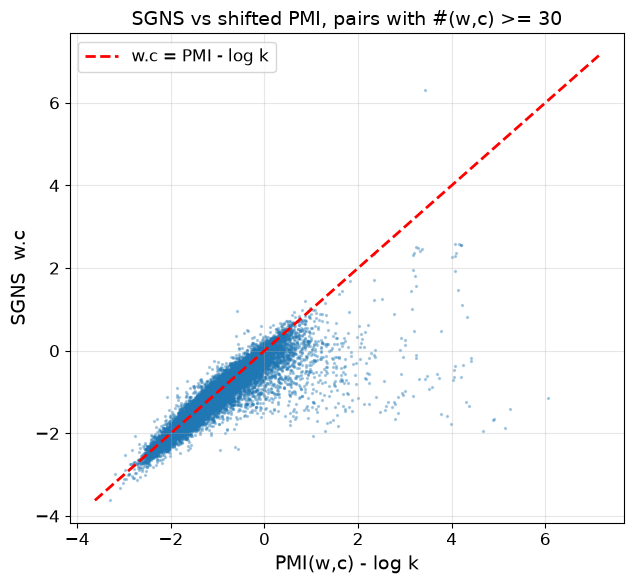

In [15]:
Cc = C.tocoo(); LG_CORR = {}
for thr in [5, 30, 200]:
    m = Cc.data >= thr
    r_, c_ = Cc.row[m], Cc.col[m]
    target = np.log(Cc.data[m]) - np.log(nw[r_]) - np.log(k * pc_alpha[c_])
    dots = (EMB_SGNS[r_] * Ct.numpy()[c_]).sum(1)
    LG_CORR[thr] = np.corrcoef(dots, target)[0, 1]
    print(f"#(w,c) >= {thr:3d}: пар {m.sum():8,}, corr(w.c, PMI - log k) = {np.corrcoef(dots, target)[0, 1]:.3f}, "
          f"среднее (w.c - PMI + log k) = {(dots - target).mean():+.3f}")
    if thr == 30: sc_dots, sc_target = dots, target
fig, ax = plt.subplots(figsize=(6.5, 6))
sub = np.random.default_rng(0).choice(len(sc_dots), min(20000, len(sc_dots)), replace=False)
ax.scatter(sc_target[sub], sc_dots[sub], s=2, alpha=0.3)
lim = [min(sc_target.min(), sc_dots.min()), max(sc_target.max(), sc_dots.max())]
ax.plot(lim, lim, "r--", lw=2, label="w.c = PMI - log k")
ax.set_xlabel("PMI(w,c) - log k", fontsize=14); ax.set_ylabel("SGNS  w.c", fontsize=14)
ax.set_title("SGNS vs shifted PMI, pairs with #(w,c) >= 30", fontsize=14); ax.legend(fontsize=12)
ax.tick_params(labelsize=12); plt.tight_layout(); plt.show()

**Что видно.** Теорема Леви–Голдберга подтверждается тем лучше, чем больше статистики у пары: корреляция $w^\top c$ со сдвинутым PMI равна 0,619 для пар с $\#(w,c)\ge 5$, 0,879 для $\ge 30$ и 0,976 для $\ge 200$, а среднее отклонение уменьшается с $-0{,}35$ до $-0{,}01$. На диаграмме точки лежат вдоль прямой $w^\top c = \mathrm{PMI} - \log k$. Вниз отклоняются пары с большим PMI: оптимум для них требует больших скалярных произведений, а ранг 100 и 3 эпохи этого не дают.

### 11.5. Анизотропия

Эмбеддинги часто занимают узкий конус: косинус между случайными словами в среднем положителен. Для SGNS это описали Mimno и Thompson: векторы слов лежат в узком конусе, направленном противоположно векторам контекстов, а степень концентрации зависит от соотношения положительных и отрицательных примеров ([Mimno & Thompson, 2017](https://aclanthology.org/D17-1308/)). Простое центрирование (вычитание среднего вектора) убирает общую компоненту ([Mu & Viswanath, 2018](https://arxiv.org/abs/1702.01417)).

In [16]:
rng_ = np.random.default_rng(0)
ia, ib = rng_.integers(0, V, 20000), rng_.integers(0, V, 20000)
def mean_cos(E):
    En = E / np.linalg.norm(E, axis=1, keepdims=True); return (En[ia] * En[ib]).sum(1).mean()
for name, E in [("PPMI-SVD", EMB_SVD), ("SGNS", EMB_SGNS)]:
    print(f"{name:9s} средний косинус случайных пар: {mean_cos(E):+.3f}, после центрирования: {mean_cos(E - E.mean(0)):+.3f}")

PPMI-SVD  средний косинус случайных пар: +0.072, после центрирования: +0.002
SGNS      средний косинус случайных пар: +0.814, после центрирования: +0.012


**Что видно.** Средний косинус случайных пар слов у SGNS 0,814 — векторы лежат в узком конусе; у PPMI-SVD 0,072. После вычитания среднего вектора оба значения близки к нулю (0,012 и 0,002). Анизотропия SGNS связана с отрицательным сэмплированием ([Mimno & Thompson, 2017](https://aclanthology.org/D17-1308/)); перед поиском соседей её стоит убирать центрированием.

## 12. Символьные n-граммные модели: Лаплас против Кнезера–Ная

Корпус — Tiny Shakespeare ([Karpathy, char-rnn](https://github.com/karpathy/char-rnn)). Первые 90% текста — обучение, последние 10% — валидация; это же разбиение используют RNN в разделе 15 и Mini-GPT в лекции 2. Качество измеряем в битах на символ (bpc):

$
\text{bpc} = -\frac{1}{N}\sum_{i=1}^{N}\log_2 P(x_i \mid x_{<i}), \qquad \text{PPL}_{\text{char}} = 2^{\text{bpc}}.
$

Модель Кнезера–Ная — интерполированный вариант с одной скидкой $D_m = n_1/(n_1 + 2n_2)$ на каждый порядок, где $n_r$ — число $m$-грамм, встретившихся ровно $r$ раз ([Chen & Goodman, 1998](https://dash.harvard.edu/entities/publication/73120378-fb0f-6bd4-e053-0100007fdf3b)). Для старшего порядка берутся обычные счётчики, для младших — счётчики продолжений $N_{1+}(\bullet\, h\, w)$: сколько различных символов стоит перед $h w$. Нижний уровень рекурсии — равномерное распределение по алфавиту, поэтому вероятность любого символа положительна.

Реализация работает со строками, поэтому подходит для любой последовательности дискретных символов. Ниже этим воспользуемся: закодируем BPE-токены символами Unicode и обучим ту же модель на токенах.

In [17]:
n_sh = int(0.9 * len(SH)); SH_TRAIN, SH_VAL = SH[:n_sh], SH[n_sh:]
print(f"обучение {len(SH_TRAIN):,} символов, валидация {len(SH_VAL):,}; алфавит {len(set(SH))} символов")

class NGramLM:
    def __init__(self, text, n, alphabet):
        self.n, self.V = n, len(alphabet)
        self.raw = [collections.Counter() for _ in range(n + 1)]       # raw[m][g]: число вхождений m-граммы g
        for m in range(1, n + 1):
            self.raw[m].update(text[i:i + m] for i in range(len(text) - m + 1))
        self.cont = [collections.Counter() for _ in range(n + 1)]      # cont[m][g]: N1+(. g)
        for m in range(1, n):
            for g in self.raw[m + 1]: self.cont[m][g[1:]] += 1
        self.stats = {}                    # для каждого контекста: (сумма счётчиков, число различных продолжений)
        for kind, table in [("raw", self.raw), ("cont", self.cont)]:
            for m in range(1, n + 1):
                st = collections.defaultdict(lambda: [0, 0])
                for g, c in table[m].items():
                    s_ = st[g[:-1]]; s_[0] += c; s_[1] += 1
                self.stats[kind, m] = st
        self.D = {}
        for kind, table in [("raw", self.raw), ("cont", self.cont)]:
            for m in range(1, n + 1):
                cs = collections.Counter(table[m].values()); n1, n2 = cs[1], cs[2]
                self.D[kind, m] = n1 / (n1 + 2 * n2) if n1 + n2 > 0 else 0.5

    def p_kn(self, h, w, m=None, top=True):
        """P_KN(w | последние m-1 символов h)."""
        if m is None: m = min(self.n, len(h) + 1)
        if m == 0: return 1.0 / self.V
        h = h[len(h) - (m - 1):] if m > 1 else ""
        kind = "raw" if top else "cont"
        lower = self.p_kn(h[1:] if m > 1 else "", w, m - 1, top=False)
        st = self.stats[kind, m].get(h)
        if st is None: return lower                       # контекст не встречался: целиком отдаём вниз
        tot, types = st; D = self.D[kind, m]
        c = (self.raw if top else self.cont)[m].get(h + w, 0)
        return max(c - D, 0) / tot + D * types / tot * lower

    def p_laplace(self, h, w):
        m = min(self.n, len(h) + 1); h = h[len(h) - (m - 1):] if m > 1 else ""
        tot = self.stats["raw", m].get(h, (0, 0))[0]
        return (self.raw[m].get(h + w, 0) + 1) / (tot + self.V)

    def bits(self, text, method="kn", start=None):
        f = self.p_kn if method == "kn" else self.p_laplace
        start = self.n if start is None else start
        return -np.mean([math.log2(f(text[max(0, i - self.n + 1):i], text[i])) for i in range(start, len(text))])

ALPHA = sorted(set(SH))
NG = {}; rows_ng = []
with Timer() as tm:
    for n in range(1, S["ngram_max"] + 1):
        NG[n] = lm = NGramLM(SH_TRAIN, n, ALPHA)
        start = S["ngram_max"]             # одинаковые позиции оценки для всех n
        r = dict(n=n, laplace_tr=lm.bits(SH_TRAIN[:20000], "laplace", start), laplace_val=lm.bits(SH_VAL, "laplace", start),
                 kn_tr=lm.bits(SH_TRAIN[:20000], "kn", start), kn_val=lm.bits(SH_VAL, "kn", start),
                 ngrams=len(lm.raw[n]))
        rows_ng.append(r)
        print(f"n={n}: {r['ngrams']:>8,} различных n-грамм | Лаплас: train {r['laplace_tr']:.3f}, val {r['laplace_val']:.3f} bpc | "
              f"KN: train {r['kn_tr']:.3f}, val {r['kn_val']:.3f} bpc")
print(f"всего {tm.s:.0f} с; равномерная модель: log2({len(ALPHA)}) = {math.log2(len(ALPHA)):.3f} bpc")

обучение 1,003,854 символов, валидация 111,540; алфавит 65 символов


n=1:       65 различных n-грамм | Лаплас: train 4.750, val 4.829 bpc | KN: train 4.750, val 4.829 bpc


n=2:    1,380 различных n-грамм | Лаплас: train 3.584, val 3.581 bpc | KN: train 3.581, val 3.584 bpc


n=3:   11,228 различных n-грамм | Лаплас: train 2.883, val 2.984 bpc | KN: train 2.814, val 2.950 bpc


n=4:   48,539 различных n-грамм | Лаплас: train 2.554, val 2.817 bpc | KN: train 2.184, val 2.494 bpc


n=5:  133,293 различных n-грамм | Лаплас: train 2.767, val 3.136 bpc | KN: train 1.816, val 2.278 bpc


n=6:  264,623 различных n-грамм | Лаплас: train 3.235, val 3.741 bpc | KN: train 1.537, val 2.248 bpc


n=7:  413,620 различных n-грамм | Лаплас: train 3.721, val 4.366 bpc | KN: train 1.298, val 2.258 bpc
всего 11 с; равномерная модель: log2(65) = 6.022 bpc


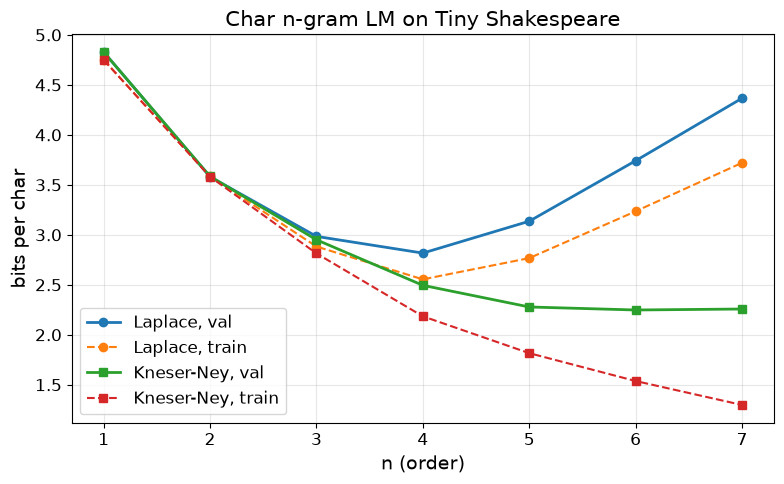

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ns = [r["n"] for r in rows_ng]
ax.plot(ns, [r["laplace_val"] for r in rows_ng], "o-", lw=2, label="Laplace, val")
ax.plot(ns, [r["laplace_tr"] for r in rows_ng], "o--", lw=1.5, label="Laplace, train")
ax.plot(ns, [r["kn_val"] for r in rows_ng], "s-", lw=2, label="Kneser-Ney, val")
ax.plot(ns, [r["kn_tr"] for r in rows_ng], "s--", lw=1.5, label="Kneser-Ney, train")
ax.set_xlabel("n (order)", fontsize=14); ax.set_ylabel("bits per char", fontsize=14)
ax.set_title("Char n-gram LM on Tiny Shakespeare", fontsize=15); ax.legend(fontsize=12); ax.grid(alpha=0.3)
ax.tick_params(labelsize=12); plt.tight_layout(); plt.show()

**Что видно.** У Лапласа валидационный bpc минимален при $n = 4$ (2,817) и дальше растёт до 4,366 при $n = 7$: контекстов становится так много, что прибавка единицы к каждому счётчику отдаёт почти всю массу невиденным символам. Кнезер–Ней улучшается до $n = 6$ (2,248 бита на символ) и почти не меняется при $n = 7$ (2,258), хотя на обучении потеря продолжает падать до 1,298. Разрыв между обучением и валидацией растёт: модель запоминает длинные контексты. Для сравнения, равномерная модель даёт $\log_2 65 = 6{,}022$ бита.

Проверим, что KN — корректное распределение: для случайного контекста сумма вероятностей по алфавиту должна быть равна 1. Затем сгенерируем текст из лучшей по валидации модели.

In [19]:
best_n = min(rows_ng, key=lambda r: r["kn_val"])["n"]; lm = NG[best_n]
for h in ["ROMEO:\nWha", "the qu", "zzq", ""]:
    print(f"контекст {h!r:14s}: сумма P_KN по алфавиту = {sum(lm.p_kn(h[-(best_n - 1):] if best_n > 1 else '', w) for w in ALPHA):.6f}")
rng_ng = random.Random(SEED); out = "ROMEO:\n"
for _ in range(300):
    h = out[-(best_n - 1):]; p = np.array([lm.p_kn(h, w) for w in ALPHA])
    out += rng_ng.choices(ALPHA, weights=p)[0]
print(f"\n--- образец из KN-{best_n} ---\n{out}")

контекст 'ROMEO:\nWha' : сумма P_KN по алфавиту = 1.000000
контекст 'the qu'      : сумма P_KN по алфавиту = 1.000000
контекст 'zzq'         : сумма P_KN по алфавиту = 1.000000
контекст ''            : сумма P_KN по алфавиту = 1.000000



--- образец из KN-6 ---
ROMEO:
The mattern condulships, O you thine, so it is now in loss, should have not took wherefore.

Lord Oxford and a partake order I.

ESCALUS:
Has current prayer's death!
Thomas Mowbray, sir.

ESCALUS:
I' the lister, wiflicture's Angelo; well beat mean a restraining him I did people,
I am a king, where s


**Что видно.** Суммы вероятностей равны 1 для всех контекстов, включая невиденный «zzq» и пустой. Текст из KN-6 локально правдоподобен: настоящие слова, имена персонажей (ESCALUS, Thomas Mowbray), формат реплик. Смысла нет, встречаются несуществующие слова (mattern, wiflicture): контекст в 5 символов не покрывает даже одного длинного слова.

### 12.1. Перплексию нельзя сравнивать между токенизаторами

Обучим на обучающей части Шекспира BPE на 1000 токенов (раздел 7) и токенную биграммную KN-модель. Токенная перплексия измеряется на другом числе событий, поэтому её нельзя сравнивать с символьной. Сопоставимая величина — биты на байт текста (bits-per-byte, bpb), или, для ASCII-текста Шекспира, биты на символ: суммарная $-\log_2 P$ делится на длину текста, а не на число токенов ([Mielke et al., 2021](https://arxiv.org/abs/2112.10508)).

In [20]:
bpe_sh = BPE(bpe_train(SH_TRAIN, 1000, verbose=False))
def as_str(ids): return "".join(chr(0x4E00 + i) for i in ids)   # каждый токен -> один символ Unicode
tr_ids, va_ids = bpe_sh.encode(SH_TRAIN), bpe_sh.encode(SH_VAL)
assert bpe_sh.decode(va_ids) == SH_VAL
TOK_ALPHA = [chr(0x4E00 + i) for i in range(256 + len(bpe_sh.merges))]
va_bytes = len(SH_VAL.encode("utf-8"))
print(f"BPE-1000: {len(va_ids):,} токенов на валидации, {va_bytes / len(va_ids):.2f} байта на токен")
for n in [1, 2, 3]:
    tlm = NGramLM(as_str(tr_ids), n, TOK_ALPHA)
    bits_tok = tlm.bits(as_str(va_ids), "kn", start=0)
    total = bits_tok * len(va_ids)
    print(f"токенная KN, n={n}: {bits_tok:6.3f} бит/токен, PPL_token = {2 ** bits_tok:8.1f} | "
          f"{total / va_bytes:.3f} бит/байт (= бит/символ для ASCII)")
for n in [2, 3, 5]:
    r = rows_ng[n - 1]
    print(f"символьная KN, n={n}: {r['kn_val']:.3f} бит/символ, PPL_char = {2 ** r['kn_val']:.2f}")

BPE-1000: 49,995 токенов на валидации, 2.23 байта на токен


токенная KN, n=1:  8.183 бит/токен, PPL_token =    290.6 | 3.668 бит/байт (= бит/символ для ASCII)


токенная KN, n=2:  5.784 бит/токен, PPL_token =     55.1 | 2.593 бит/байт (= бит/символ для ASCII)


токенная KN, n=3:  5.069 бит/токен, PPL_token =     33.6 | 2.272 бит/байт (= бит/символ для ASCII)
символьная KN, n=2: 3.584 бит/символ, PPL_char = 11.99
символьная KN, n=3: 2.950 бит/символ, PPL_char = 7.73
символьная KN, n=5: 2.278 бит/символ, PPL_char = 4.85


**Что видно.** Токенная биграмма над BPE-1000 имеет перплексию 55,1 на токен, символьная биграмма — 11,99 на символ, и по перплексии первая выглядит в 4,6 раза хуже. Но токен покрывает в среднем 2,23 байта, и в битах на символ токенная биграмма (2,593) заметно лучше символьной (3,584). Токенная триграмма (2,272) почти догоняет символьную KN-5 (2,278). Перплексии при разных токенизациях несравнимы, биты на байт — сравнимы.

## 13. Градиенты нейронной языковой модели вручную

### 13.1. Softmax и кросс-энтропия

Для логитов $z$ и правильного класса $y$ потеря $\ell = -\log \mathrm{softmax}(z)_y$ имеет градиент $\nabla_z \ell = p - e_y$, где $p = \mathrm{softmax}(z)$ (раздел 5.1). Якобиан softmax равен $J = \mathrm{diag}(p) - p p^\top$. Сверим обе формулы с autograd.

In [21]:
g = torch.Generator().manual_seed(1)
z = torch.randn(65, dtype=torch.float64, generator=g, requires_grad=True); y = 7
loss = F.cross_entropy(z[None], torch.tensor([y])); loss.backward()
p = torch.softmax(z.detach(), 0)
print(f"|grad_autograd - (p - e_y)|_max = {(z.grad - (p - F.one_hot(torch.tensor(y), 65))).abs().max().item():.2e}")
J_auto = torch.autograd.functional.jacobian(lambda t: torch.softmax(t, 0), z.detach())
J_formula = torch.diag(p) - torch.outer(p, p)
print(f"|J_autograd - (diag(p) - pp^T)|_max = {(J_auto - J_formula).abs().max().item():.2e}")
print(f"сумма градиента по логитам = {z.grad.sum().item():+.2e} (должна быть 0: softmax не меняется от сдвига логитов)")

|grad_autograd - (p - e_y)|_max = 2.78e-17
|J_autograd - (diag(p) - pp^T)|_max = 3.47e-18
сумма градиента по логитам = +0.00e+00 (должна быть 0: softmax не меняется от сдвига логитов)


**Что видно.** Градиент кросс-энтропии по логитам совпадает с $p - e_y$, а якобиан softmax — с $\mathrm{diag}(p) - pp^\top$ с точностью до $10^{-17}$; сумма градиента по логитам равна нулю.

### 13.2. Обратное распространение во времени для простой RNN

Простая RNN: $h_t = \tanh(a_t)$, $a_t = W h_{t-1} + U x_t + b$, $o_t = V h_t + c$, $\ell = \sum_t \mathrm{CE}(o_t, y_t)$. Обратный проход (BPTT) идёт от последнего шага к первому:

$
\delta^o_t = p_t - e_{y_t},\qquad
g_t = V^\top \delta^o_t + W^\top \delta^a_{t+1},\qquad
\delta^a_t = g_t \odot (1 - h_t^2),
$
$
\nabla_W = \sum_t \delta^a_t h_{t-1}^\top,\quad \nabla_U = \sum_t \delta^a_t x_t^\top,\quad \nabla_V = \sum_t \delta^o_t h_t^\top .
$

Реализуем этот проход вручную и сравним с autograd.

In [22]:
def rnn_manual(params, xs, ys, h0):
    W, U, b, Vo, c = params
    hs, ps, h = [h0], [], h0
    for x in xs:                                                     # прямой проход
        h = torch.tanh(W @ h + U @ x + b); hs.append(h)
        ps.append(torch.softmax(Vo @ h + c, 0))
    loss = -sum(torch.log(p[y]) for p, y in zip(ps, ys))
    gW, gU, gb, gV, gc = [torch.zeros_like(t) for t in params]
    da_next = torch.zeros_like(h0)
    for t in reversed(range(len(xs))):                               # обратный проход
        do = ps[t].clone(); do[ys[t]] -= 1
        gV += torch.outer(do, hs[t + 1]); gc += do
        gh = Vo.T @ do + W.T @ da_next
        da = gh * (1 - hs[t + 1] ** 2)
        gW += torch.outer(da, hs[t]); gU += torch.outer(da, xs[t]); gb += da
        da_next = da
    return loss, [gW, gU, gb, gV, gc]

H, Vc, T_ = 16, 10, 12
g = torch.Generator().manual_seed(2)
params = [torch.randn(H, H, dtype=torch.float64, generator=g) * 0.4, torch.randn(H, Vc, dtype=torch.float64, generator=g) * 0.4,
          torch.zeros(H, dtype=torch.float64), torch.randn(Vc, H, dtype=torch.float64, generator=g) * 0.4, torch.zeros(Vc, dtype=torch.float64)]
seq = torch.randint(0, Vc, (T_ + 1,), generator=g)
xs = [F.one_hot(seq[t], Vc).double() for t in range(T_)]; ys = [int(seq[t + 1]) for t in range(T_)]
h0 = torch.zeros(H, dtype=torch.float64)
loss_m, grads_m = rnn_manual(params, xs, ys, h0)
P = [p.clone().requires_grad_(True) for p in params]
loss_a, _ = rnn_manual(P, xs, ys, h0); loss_a.backward()
for name, gm, pa in zip(["W", "U", "b", "V", "c"], grads_m, P):
    print(f"d loss / d {name}: max |ручной - autograd| = {(gm - pa.grad).abs().max().item():.2e}")

d loss / d W: max |ручной - autograd| = 2.22e-15
d loss / d U: max |ручной - autograd| = 1.78e-15
d loss / d b: max |ручной - autograd| = 1.11e-15
d loss / d V: max |ручной - autograd| = 4.44e-16
d loss / d c: max |ручной - autograd| = 1.11e-16


**Что видно.** Ручной BPTT совпадает с autograd по всем пяти группам параметров с ошибкой не больше $2{,}2\cdot 10^{-15}$.

## 14. Затухание и взрыв градиентов

Градиент потери последнего шага по раннему скрытому состоянию — произведение якобианов (раздел 5.3):

$
\frac{\partial L_T}{\partial h_t} = \Big(\prod_{s=t+1}^{T} \frac{\partial h_s}{\partial h_{s-1}}\Big)^{\!\top} \frac{\partial L_T}{\partial h_T},
\qquad \frac{\partial h_s}{\partial h_{s-1}} = \mathrm{diag}(1 - h_s^2)\, W .
$

Поэтому $\|\partial L_T/\partial h_t\| \le (\gamma\, \sigma_{\max}(W))^{T-t}\, \|\partial L_T/\partial h_T\|$, где $\gamma \le 1$ — верхняя граница производной $\tanh$ ([Pascanu et al., 2013](https://arxiv.org/abs/1211.5063)). Если $\sigma_{\max}(W) < 1$, градиент затухает экспоненциально. Если наибольшее собственное значение больше 1, градиент может взорваться.

Эксперимент: RNN со скрытым размером 128 на реальных символах Шекспира. $W = \rho\, Q$, где $Q$ — случайная ортогональная матрица, поэтому все сингулярные числа $W$ равны $\rho$. Для линейной RNN ($h_s = W h_{s-1} + U x_s$) теория даёт точно $\|\partial L_T/\partial h_{T-k}\| = \rho^k \|\partial L_T/\partial h_T\|$. Это хорошая проверка измерений. Для сравнения — необученная LSTM. Со стандартной инициализацией PyTorch смещения гейтов около нуля, и гейт забывания $f \approx \sigma(0) = 0.5$. Градиент по ячейке памяти умножается на $f$ на каждом шаге, поэтому добавим вариант со смещением гейта забывания 1 и 3. Инициализацию смещением 1 рекомендуют Jozefowicz и соавторы ([Jozefowicz et al., 2015](https://proceedings.mlr.press/v37/jozefowicz15.html)).

In [23]:
CH = sorted(set(SH)); STOI = {ch: i for i, ch in enumerate(CH)}; NV = len(CH)
SH_TR_IDS = torch.tensor([STOI[ch] for ch in SH_TRAIN]); SH_VA_IDS = torch.tensor([STOI[ch] for ch in SH_VAL])
T_len, Hd = 200, 128
x_ids = SH_TR_IDS[10000:10000 + T_len]

def grad_profile(rho, act="tanh", seed=0):
    g = torch.Generator().manual_seed(seed)
    Q, _ = torch.linalg.qr(torch.randn(Hd, Hd, generator=g, dtype=torch.float64))
    W = rho * Q; Uin = torch.randn(Hd, NV, generator=g, dtype=torch.float64) / math.sqrt(NV) * 3
    Vout = torch.randn(NV, Hd, generator=g, dtype=torch.float64) / math.sqrt(Hd)
    h = torch.zeros(Hd, dtype=torch.float64, requires_grad=True); hs = []   # float64: при rho=1.5 значения до 1e35
    for t in range(T_len):
        a = W @ h + Uin[:, x_ids[t]]
        h = torch.tanh(a) if act == "tanh" else a
        h.retain_grad(); hs.append(h)
    loss = F.cross_entropy((Vout @ h)[None], x_ids[-1:])
    loss.backward()
    return np.array([hs[T_len - 1 - k].grad.norm().item() for k in range(T_len)])

def grad_profile_lstm(forget_bias=None, seed=0):
    torch.manual_seed(seed)
    cell = nn.LSTMCell(NV, Hd).double(); Vout = torch.randn(NV, Hd, dtype=torch.float64) / math.sqrt(Hd)
    if forget_bias is not None:                   # порядок гейтов в PyTorch: i, f, g, o
        with torch.no_grad(): cell.bias_ih[Hd:2 * Hd] = forget_bias; cell.bias_hh[Hd:2 * Hd] = 0
    h, c = torch.zeros(1, Hd, dtype=torch.float64, requires_grad=True), torch.zeros(1, Hd, dtype=torch.float64); hs = []
    for t in range(T_len):
        h, c = cell(F.one_hot(x_ids[t], NV).double()[None], (h, c)); h.retain_grad(); hs.append(h)
    F.cross_entropy(h @ Vout.T, x_ids[-1:]).backward()
    return np.array([hs[T_len - 1 - k].grad.norm().item() for k in range(T_len)])

PROF = {}
for rho in [0.5, 0.9, 1.0, 1.5]:
    PROF[f"linear, rho={rho}"] = grad_profile(rho, "linear")
    PROF[f"tanh, rho={rho}"] = grad_profile(rho, "tanh")
PROF["LSTM (default init)"] = grad_profile_lstm()
PROF["LSTM, forget bias 1"] = grad_profile_lstm(1.0)
PROF["LSTM, forget bias 3"] = grad_profile_lstm(3.0)
for k in [10, 50]:
    for rho in [0.5, 0.9, 1.5]:
        pr = PROF[f"linear, rho={rho}"]
        print(f"linear, rho={rho}: ||g_(T-{k})|| / ||g_T|| = {pr[k] / pr[0]:.3e}, теория rho^{k} = {rho ** k:.3e}")
print()
for name, pr in PROF.items():
    print(f"{name:22s} ||g_(T-k)|| / ||g_T||: k=10: {pr[10] / pr[0]:.2e}, k=50: {pr[50] / pr[0]:.2e}, k=150: {pr[150] / pr[0]:.2e}")

linear, rho=0.5: ||g_(T-10)|| / ||g_T|| = 9.766e-04, теория rho^10 = 9.766e-04
linear, rho=0.9: ||g_(T-10)|| / ||g_T|| = 3.487e-01, теория rho^10 = 3.487e-01
linear, rho=1.5: ||g_(T-10)|| / ||g_T|| = 5.767e+01, теория rho^10 = 5.767e+01
linear, rho=0.5: ||g_(T-50)|| / ||g_T|| = 8.882e-16, теория rho^50 = 8.882e-16
linear, rho=0.9: ||g_(T-50)|| / ||g_T|| = 5.154e-03, теория rho^50 = 5.154e-03
linear, rho=1.5: ||g_(T-50)|| / ||g_T|| = 6.376e+08, теория rho^50 = 6.376e+08

linear, rho=0.5        ||g_(T-k)|| / ||g_T||: k=10: 9.77e-04, k=50: 8.88e-16, k=150: 7.01e-46
tanh, rho=0.5          ||g_(T-k)|| / ||g_T||: k=10: 2.78e-04, k=50: 1.56e-18, k=150: 5.59e-54
linear, rho=0.9        ||g_(T-k)|| / ||g_T||: k=10: 3.49e-01, k=50: 5.15e-03, k=150: 1.37e-07
tanh, rho=0.9          ||g_(T-k)|| / ||g_T||: k=10: 5.90e-02, k=50: 5.30e-07, k=150: 8.46e-20
linear, rho=1.0        ||g_(T-k)|| / ||g_T||: k=10: 1.00e+00, k=50: 1.00e+00, k=150: 1.00e+00
tanh, rho=1.0          ||g_(T-k)|| / ||g_T||: k=10: 1.3

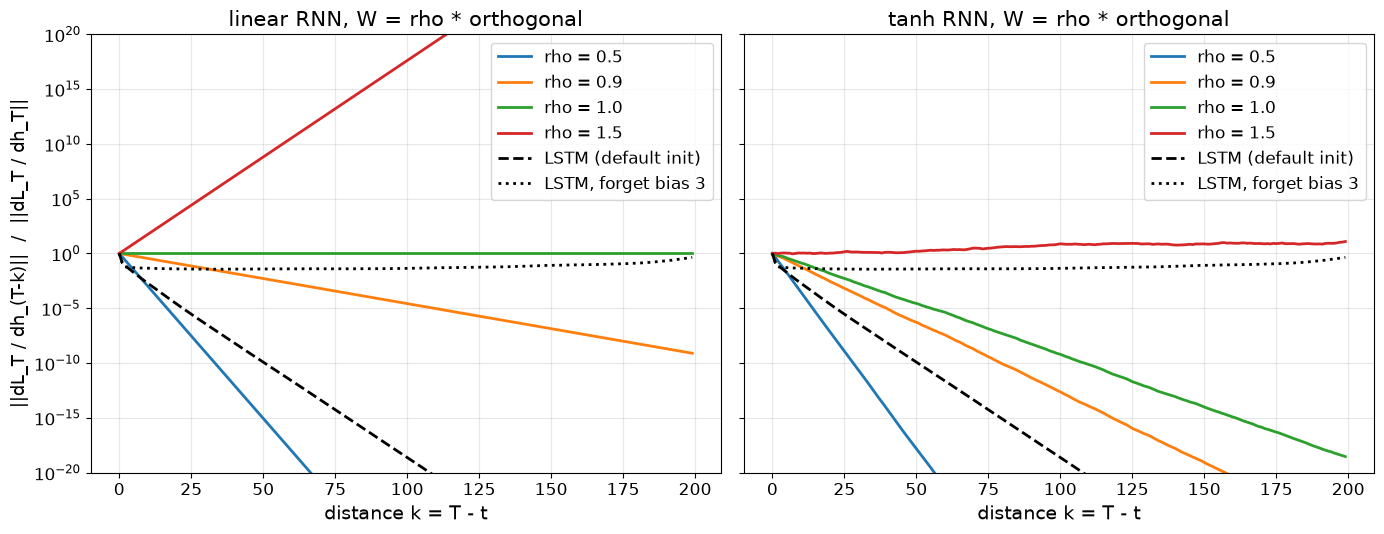

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, act in zip(axes, ["linear", "tanh"]):
    for rho in [0.5, 0.9, 1.0, 1.5]:
        pr = PROF[f"{act}, rho={rho}"]; ax.semilogy(pr / pr[0], lw=2, label=f"rho = {rho}")
    for name, st in [("LSTM (default init)", "k--"), ("LSTM, forget bias 3", "k:")]:
        pr = PROF[name]; ax.semilogy(pr / pr[0], st, lw=2, label=name)
    ax.set_title(f"{act} RNN, W = rho * orthogonal", fontsize=15)
    ax.set_xlabel("distance k = T - t", fontsize=14); ax.legend(fontsize=12); ax.grid(alpha=0.3)
    ax.tick_params(labelsize=12); ax.set_ylim(1e-20, 1e20)
axes[0].set_ylabel("||dL_T / dh_(T-k)||  /  ||dL_T / dh_T||", fontsize=13)
plt.tight_layout(); plt.show()

**Что видно.** Для линейной RNN с $W = \rho Q$ отношение норм градиентов в точности равно $\rho^k$: $0{,}9^{50} = 5{,}15\cdot 10^{-3}$, $1{,}5^{50} = 6{,}4\cdot 10^{8}$, а при $\rho = 1$ норма сохраняется. С tanh затухание только сильнее, потому что $\tanh' \le 1$: даже при $\rho = 1$ на расстоянии 150 остаётся $10^{-14}$. При $\rho = 1{,}5$ tanh насыщается и не даёт градиенту взорваться (7,46 при $k = 150$), зато сеть теряет чувствительность к входу. LSTM со стандартной инициализацией затухает почти как tanh-RNN ($4\cdot 10^{-28}$ при $k = 150$). Смещение гейта забывания 1 даёт $1{,}3\cdot 10^{-9}$, а смещение 3 держит отношение в диапазоне $10^{-2}$–$10^{-1}$ на всех 200 шагах: $\sigma(3)^{50} \approx 0{,}09$, измерено 0,039 — тот же порядок.

### 14.1. Спектральный радиус и наибольшее сингулярное число

У ортогональной матрицы все сингулярные числа равны модулям собственных значений. У гауссовой матрицы это не так: можно иметь спектральный радиус $\rho(W) < 1$ и при этом $\sigma_{\max}(W) > 1$. Тогда на коротких расстояниях градиент растёт, хотя в пределе затухает: асимптотику определяет $\rho(W)$, а верхнюю оценку — $\sigma_{\max}$.

In [25]:
g = torch.Generator().manual_seed(3)
A = torch.randn(Hd, Hd, generator=g, dtype=torch.float64)
A = A / torch.linalg.eigvals(A).abs().max() * 0.95          # спектральный радиус 0.95
print(f"гауссова матрица: спектральный радиус {torch.linalg.eigvals(A).abs().max().item():.3f}, "
      f"sigma_max = {torch.linalg.matrix_norm(A, 2).item():.3f}")
v = torch.randn(Hd, generator=g, dtype=torch.float64); v = v / v.norm()
norms, M = [], torch.eye(Hd, dtype=torch.float64)
for k in range(1, 401):
    M = A.T @ M; norms.append((torch.linalg.matrix_norm(M, 2).item(), (M @ v).norm().item()))
for k in [1, 5, 20, 100, 400]:
    print(f"  k={k:3d}: ||(W^T)^k||_2 = {norms[k - 1][0]:.3e}, ||(W^T)^k v|| для случайного v = {norms[k - 1][1]:.3e}   (0.95^k = {0.95 ** k:.3e}, sigma_max^k = {torch.linalg.matrix_norm(A, 2).item() ** k:.3e})")

гауссова матрица: спектральный радиус 0.950, sigma_max = 1.844


  k=  1: ||(W^T)^k||_2 = 1.844e+00, ||(W^T)^k v|| для случайного v = 1.023e+00   (0.95^k = 9.500e-01, sigma_max^k = 1.844e+00)
  k=  5: ||(W^T)^k||_2 = 2.749e+00, ||(W^T)^k v|| для случайного v = 8.037e-01   (0.95^k = 7.738e-01, sigma_max^k = 2.134e+01)
  k= 20: ||(W^T)^k||_2 = 1.071e+00, ||(W^T)^k v|| для случайного v = 2.651e-01   (0.95^k = 3.585e-01, sigma_max^k = 2.074e+05)
  k=100: ||(W^T)^k||_2 = 1.736e-02, ||(W^T)^k v|| для случайного v = 2.203e-03   (0.95^k = 5.921e-03, sigma_max^k = 3.841e+26)
  k=400: ||(W^T)^k||_2 = 3.714e-09, ||(W^T)^k v|| для случайного v = 4.562e-10   (0.95^k = 1.229e-09, sigma_max^k = 2.177e+106)


**Что видно.** При спектральном радиусе 0,95 у гауссовой матрицы $\sigma_{\max} = 1{,}84$, и норма $\|(W^\top)^k\|$ сначала растёт (2,75 при $k = 5$) и только потом убывает, в итоге примерно как $0{,}95^k$: $3{,}7\cdot 10^{-9}$ против $1{,}2\cdot 10^{-9}$ при $k = 400$. Оценка через $\sigma_{\max}^k$ ($2\cdot 10^{106}$) бесполезна: асимптотику определяет $\rho$, а переходный рост — несимметричность матрицы.

## 15. Символьные RNN и LSTM на Шекспире

Модели одного размера: скрытое состояние `rnn_hidden`, вход — обучаемое вложение символа размерности 64. Обучение идёт на случайных фрагментах длины `rnn_seq` из обучающей части, BPTT на длину фрагмента. Валидация: весь валидационный текст разбит на 16 параллельных потоков. Скрытое состояние переносится между окнами, поэтому модель видит длинный контекст.

Сначала короткий эксперимент с взрывом градиента, затем основное обучение.

In [26]:
class CharRNN(nn.Module):
    def __init__(self, kind, hidden, emb=64):
        super().__init__()
        self.emb = nn.Embedding(NV, emb)
        self.rnn = (nn.LSTM if kind == "lstm" else nn.RNN)(emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, NV)
        if kind == "lstm":
            with torch.no_grad():
                for name, p in self.rnn.named_parameters():
                    if "bias_ih" in name: p[hidden:2 * hidden] = 1.0      # гейт забывания
                    if "bias_hh" in name: p[hidden:2 * hidden] = 0.0
    def forward(self, x, state=None):
        h, state = self.rnn(self.emb(x), state)
        return self.out(h), state

def get_batch(ids, bs, T, gen):
    ix = torch.randint(0, len(ids) - T - 1, (bs,), generator=gen)
    x = torch.stack([ids[i:i + T] for i in ix]); y = torch.stack([ids[i + 1:i + T + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def eval_bpc(model, ids, streams=16, win=256, temperature=1.0, return_entropy=False):
    model.eval()
    L = (len(ids) - 1) // streams
    X = ids[:streams * L].view(streams, L).to(DEVICE); Y = ids[1:streams * L + 1].view(streams, L).to(DEVICE)
    state, nll, ent, n = None, 0.0, 0.0, 0
    for s in range(0, L, win):
        logits, state = model(X[:, s:s + win], state)
        logp = F.log_softmax(logits.float() / temperature, -1)
        nll += -logp.gather(-1, Y[:, s:s + win, None]).sum().item()
        ent += -(logp.exp() * logp).sum().item(); n += Y[:, s:s + win].numel()
    model.train()
    bpc = nll / n / math.log(2)
    return (bpc, ent / n / math.log(2)) if return_entropy else bpc

def train_char(kind, clip, steps=S["rnn_steps"], opt="adam", lr=S["rnn_lr"], rho=None, n_val=5, seed=SEED):
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    model = CharRNN(kind, S["rnn_hidden"]).to(DEVICE)
    if rho is not None:                                  # W_hh = rho * ортогональная матрица
        with torch.no_grad():
            Q, _ = torch.linalg.qr(torch.randn(S["rnn_hidden"], S["rnn_hidden"], generator=gen))
            model.rnn.weight_hh_l0.copy_(rho * Q)
    if opt == "adam":
        optim = torch.optim.Adam(model.parameters(), lr=lr)
        sched = torch.optim.lr_scheduler.LambdaLR(optim, lambda i: 0.5 * (1 + math.cos(math.pi * i / steps)))   # косинусное убывание
    else:
        optim = torch.optim.SGD(model.parameters(), lr=lr); sched = None
    log = dict(step=[], loss=[], gnorm=[], val=[])
    for it in range(1, steps + 1):
        x, y = get_batch(SH_TR_IDS, S["rnn_bs"], S["rnn_seq"], gen)
        logits, _ = model(x)
        loss = F.cross_entropy(logits.reshape(-1, NV), y.reshape(-1))
        optim.zero_grad(set_to_none=True); loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), clip if clip else float("inf"))
        optim.step()
        if sched: sched.step()
        log["step"].append(it); log["loss"].append(loss.item() / math.log(2)); log["gnorm"].append(gn.item())
        if n_val and it % (steps // n_val) == 0:
            log["val"].append((it, eval_bpc(model, SH_VA_IDS)))
    return model, log

### 15.1. Взрыв градиента и clipping

С Adam и стандартной инициализацией простая RNN на этой задаче обучается спокойно: норма градиента не растёт. Чтобы увидеть взрыв, создадим условия из раздела 14: $W_{hh} = 1.2\,Q$ (все сингулярные числа 1.2) и обычный SGD с шагом 1, у которого размер шага пропорционален норме градиента. Сравним 400 шагов без ограничения градиента и с ограничением нормы порогом 1.

SGD, rho=1.2, no clip :   12 с | потеря последних 100 шагов 6.997 бит/символ, максимум после шага 50: 35.82 | норма градиента: медиана 4.17, максимум 2.69e+04


SGD, rho=1.2, clip 1  :   12 с | потеря последних 100 шагов 2.712 бит/символ, максимум после шага 50: 3.52 | норма градиента: медиана 0.53, максимум 7.2


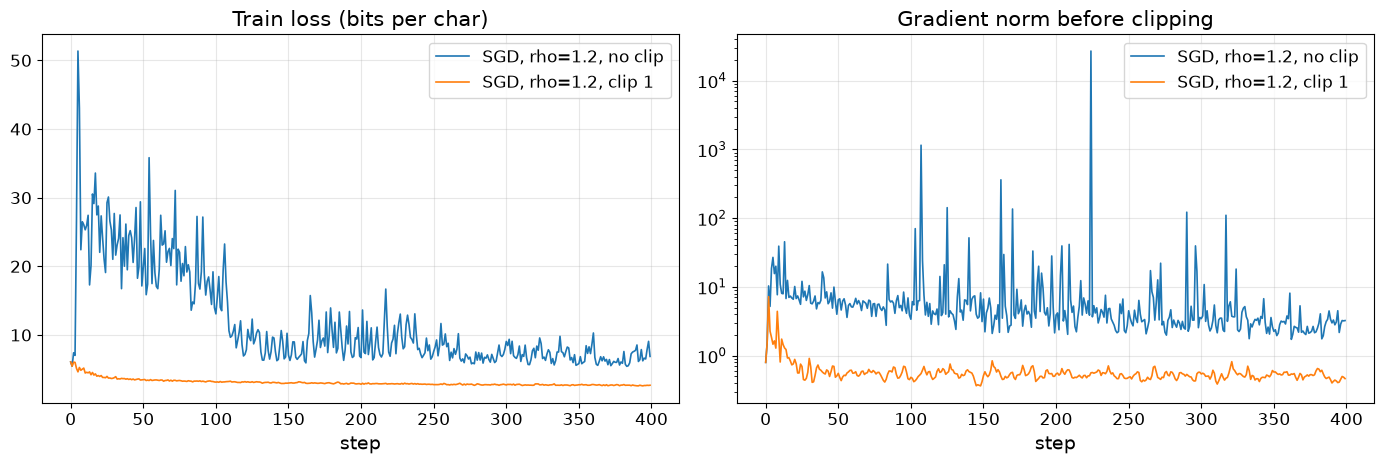

In [27]:
CLIP_RUNS = {}
for name, clip in [("SGD, rho=1.2, no clip", None), ("SGD, rho=1.2, clip 1", 1.0)]:
    with Timer() as tm: _, log = train_char("rnn", clip, steps=400, opt="sgd", lr=1.0, rho=1.2, n_val=0)
    CLIP_RUNS[name] = log; L, G = np.array(log["loss"]), np.array(log["gnorm"])
    print(f"{name:22s}: {tm.s:4.0f} с | потеря последних 100 шагов {np.nanmean(L[-100:]):.3f} бит/символ, максимум после шага 50: {np.nanmax(L[50:]):.2f} | "
          f"норма градиента: медиана {np.median(G):.2f}, максимум {np.nanmax(G):.3g}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, log in CLIP_RUNS.items():
    axes[0].plot(log["loss"], lw=1.2, label=name); axes[1].semilogy(log["gnorm"], lw=1.2, label=name)
axes[0].set_title("Train loss (bits per char)", fontsize=15); axes[1].set_title("Gradient norm before clipping", fontsize=15)
for ax in axes:
    ax.set_xlabel("step", fontsize=14); ax.legend(fontsize=12); ax.grid(alpha=0.3); ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

**Что видно.** Без клиппинга SGD с шагом 1 разваливается: потеря подскакивает до 50 бит на символ, норма градиента доходит до $2{,}7\cdot 10^{4}$, и к 400-му шагу потеря остаётся около 7,0 бита — хуже равномерной модели (6,02). С клиппингом нормы до 1 та же сеть ровно учится до 2,71 бита, медиана нормы градиента 0,53. Клиппинг не устраняет причину взрыва ($\rho(W_{hh}) = 1{,}2$), но ограничивает длину шага, и редкие всплески больше не выбрасывают параметры в плохую область.

### 15.2. Основное обучение: RNN против LSTM

Обе модели: Adam, шаг `rnn_lr` с косинусным убыванием, ограничение нормы градиента 1. У LSTM смещение гейта забывания равно 1.

In [28]:
RUNS = {}
for name, kind in [("RNN", "rnn"), ("LSTM", "lstm")]:
    with Timer() as tm: model, log = train_char(kind, 1.0)
    RUNS[name] = (model, log)
    gn = np.array(log["gnorm"])
    print(f"{name:5s}: {tm.s:5.0f} с, {sum(p.numel() for p in model.parameters()):,} параметров | "
          f"val bpc по ходу: {', '.join(f'{v:.3f}' for _, v in log['val'])} | "
          f"норма градиента: медиана {np.median(gn):.2f}, максимум {gn.max():.1f}")

RNN  :   130 с, 103,297 параметров | val bpc по ходу: 2.429, 2.341, 2.295, 2.269, 2.262 | норма градиента: медиана 0.32, максимум 2.2


LSTM :   232 с, 350,593 параметров | val bpc по ходу: 2.397, 2.273, 2.217, 2.199, 2.193 | норма градиента: медиана 0.21, максимум 0.8


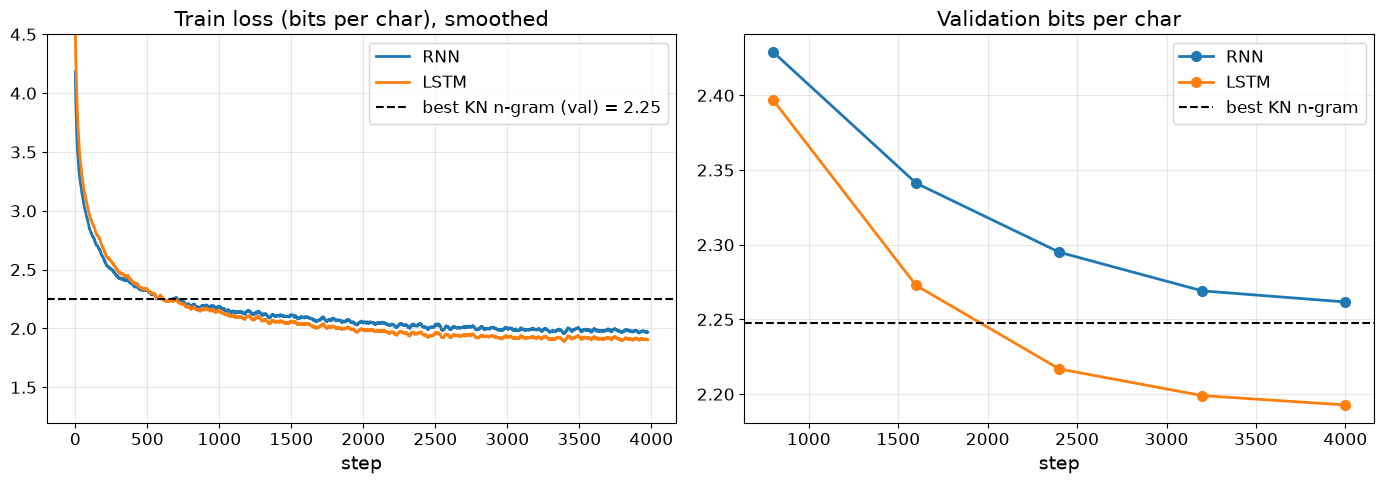

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
def smooth(a, w=25): return np.convolve(a, np.ones(w) / w, mode="valid")
for name, (_, log) in RUNS.items():
    axes[0].plot(smooth(log["loss"]), lw=2, label=name)
best_kn = min(r["kn_val"] for r in rows_ng)
axes[0].axhline(best_kn, color="k", ls="--", lw=1.5, label=f"best KN n-gram (val) = {best_kn:.2f}")
for name, (_, log) in RUNS.items():
    vs_, vv_ = zip(*log["val"]); axes[1].plot(vs_, vv_, "o-", lw=2, ms=7, label=name)
axes[1].axhline(best_kn, color="k", ls="--", lw=1.5, label="best KN n-gram")
axes[0].set_ylim(1.2, 4.5); axes[0].set_title("Train loss (bits per char), smoothed", fontsize=15)
axes[1].set_title("Validation bits per char", fontsize=15)
for ax in axes:
    ax.set_xlabel("step", fontsize=14); ax.legend(fontsize=12); ax.grid(alpha=0.3); ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

**Что видно.** За 4000 шагов LSTM доходит до 2,193 бита на символ на валидации и обгоняет лучшую n-граммную модель KN-6 (2,248) примерно после 2000 шагов. Простая RNN останавливается на 2,262 и до KN не дотягивает. Обучение заняло 130 с для RNN и 232 с для LSTM. Потеря на обучении к концу около 1,9–2,0 бита, то есть разрыв с валидацией около 0,25 бита, а кривые ещё не вышли на плато: сетям не хватает шагов. Максимальная норма градиента у LSTM 0,8, у RNN 2,2 — LSTM учится спокойнее.

### 15.3. Температура и энтропия

При генерации логиты делят на температуру $\tau$: $p_\tau \propto \exp(z/\tau)$. При $\tau < 1$ распределение острее и энтропия ниже, при $\tau > 1$ — наоборот. Модель обучена минимизировать кросс-энтропию при $\tau = 1$, поэтому валидационный bpc должен быть минимален около $\tau = 1$. Если минимум сдвинут, модель плохо откалибрована.

tau = 0.50: val bpc 2.817, средняя энтропия предсказания 1.097 бит
tau = 0.70: val bpc 2.381, средняя энтропия предсказания 1.481 бит
tau = 0.85: val bpc 2.247, средняя энтропия предсказания 1.755 бит
tau = 1.00: val bpc 2.193, средняя энтропия предсказания 2.019 бит
tau = 1.15: val bpc 2.187, средняя энтропия предсказания 2.273 бит
tau = 1.30: val bpc 2.211, средняя энтропия предсказания 2.515 бит
tau = 1.50: val bpc 2.272, средняя энтропия предсказания 2.818 бит


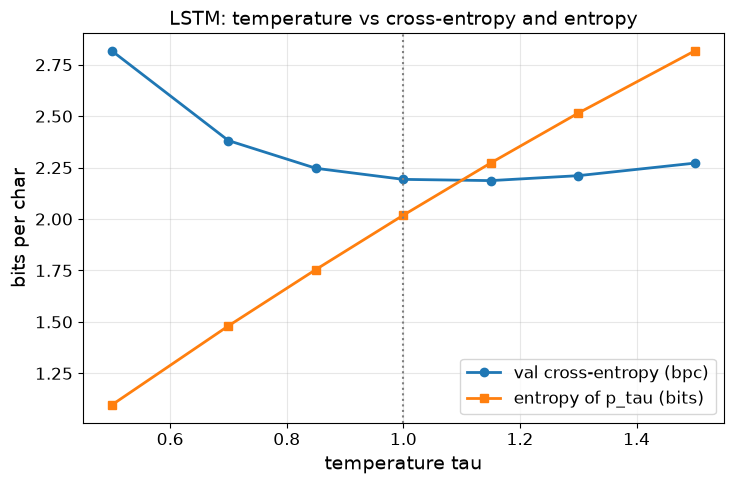


--- LSTM, tau = 0.5 ---


ROMEO:
Thou make the presence of the man and will strength
As we have weeping strange showels! Therefore that he love thee
That should be a linements to his worth of the king,
That the contrary.

First Murderer:
Say, his mild more nor such a scope the boy.


--- LSTM, tau = 1.0 ---
ROMEO:
Thou must know solenelous ane hand, in Ixelse, great upon his tweeter his
honouse hell: says him; that's your wakes, and send
And true nemer strong the stone.

Second Murderer:
Scond sound,
I can. So I fearful his fill.
Woe, he say, if come defenomen

--- LSTM, tau = 1.5 ---


ROMEO:
thoremhing her!s:
Lest Haunteral'd, id Ixelst, grecomesty hither
here hath good being such peril
stip--of torgied weach othear'd, trunk-days strook'st, yet for 'faiiness
Like tescoan shuzbs
In Brage and end, plaid-filk mooe, he sayfedged.
Underbroke 


In [30]:
lstm = RUNS["LSTM"][0]
taus = [0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5]
temp_rows = [(t, *eval_bpc(lstm, SH_VA_IDS, temperature=t, return_entropy=True)) for t in taus]
for t, b, e in temp_rows: print(f"tau = {t:4.2f}: val bpc {b:.3f}, средняя энтропия предсказания {e:.3f} бит")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(taus, [r[1] for r in temp_rows], "o-", lw=2, label="val cross-entropy (bpc)")
ax.plot(taus, [r[2] for r in temp_rows], "s-", lw=2, label="entropy of p_tau (bits)")
ax.axvline(1.0, color="gray", ls=":")
ax.set_xlabel("temperature tau", fontsize=14); ax.set_ylabel("bits per char", fontsize=14)
ax.set_title("LSTM: temperature vs cross-entropy and entropy", fontsize=14); ax.legend(fontsize=12); ax.grid(alpha=0.3)
ax.tick_params(labelsize=12); plt.tight_layout(); plt.show()

@torch.no_grad()
def sample_char(model, prompt, n, tau, seed=SEED):
    model.eval(); g = torch.Generator(device=DEVICE).manual_seed(seed)
    x = torch.tensor([[STOI[c] for c in prompt]], device=DEVICE); logits, state = model(x); out = prompt
    for _ in range(n):
        p = torch.softmax(logits[0, -1].float() / tau, -1)
        nxt = torch.multinomial(p, 1, generator=g); out += CH[nxt.item()]
        logits, state = model(nxt.view(1, 1), state)
    model.train(); return out
prompt = "ROMEO:\n"
for tau in [0.5, 1.0, 1.5]:
    print(f"\n--- LSTM, tau = {tau} ---")
    print(sample_char(lstm, prompt, 250, tau))

**Что видно.** Кросс-энтропия на валидации минимальна при $\tau = 1{,}15$ (2,187 против 2,193 при $\tau = 1$): модель слегка переуверена на новых данных. Это видно и по энтропии: при $\tau = 1$ она равна 2,02 бита, меньше реальной потери. Энтропия монотонно растёт с $\tau$. Образцы показывают цену выбора: при $\tau = 0{,}5$ текст грамматичен, но однообразен, при $\tau = 1{,}5$ появляются несуществующие слова и случайные знаки.

## 16. Сводка практикума

In [31]:
print("Токенизация (BPE-8000, свой на каждом языке):")
for lang in ["en", "ru"]:
    st = STATS[(lang, 8000)]
    print(f"  {lang}: {st['bpt']:.2f} байта UTF-8 на токен, {st['fert']:.2f} токена на слово")
print("Налог на токены (токенов RU / токенов EN на одном романе):")
for name, r in TAX.items(): print(f"  {name:40s} {r:.2f}")
print(f"\nЭмбеддинги: аналогии SVD {ANALOGY_ACC['PPMI-SVD']}/{len(ANALOGIES)}, SGNS {ANALOGY_ACC['SGNS']}/{len(ANALOGIES)}; "
      f"пересечение 10 соседей {overlap:.2f}; corr(w.c, PMI - log k) для пар с #>=30: {LG_CORR[30]:.3f}")
print("\nЯзыковые модели на Tiny Shakespeare, валидация, бит на символ:")
table = [("равномерная", math.log2(len(ALPHA)))]
table += [(f"Лаплас, n={r['n']}", r["laplace_val"]) for r in rows_ng if r["n"] in (3, 5)]
table += [(f"Кнезер-Ней, n={r['n']}", r["kn_val"]) for r in rows_ng if r["n"] in (3, 5, best_n)]
table += [(f"{name}, {S['rnn_steps']} шагов", log["val"][-1][1]) for name, (_, log) in RUNS.items()]
for name, b in table: print(f"  {name:28s} {b:.3f}")
print(f"\nрежим: {'CPU FAST_DEV_RUN' if FAST_DEV_RUN else 'GPU'}; время работы блокнота: {(time.time() - T_START) / 60:.1f} мин")

Токенизация (BPE-8000, свой на каждом языке):
  en: 4.31 байта UTF-8 на токен, 1.33 токена на слово
  ru: 6.93 байта UTF-8 на токен, 1.57 токена на слово
Налог на токены (токенов RU / токенов EN на одном романе):
  BPE-8k (en) на каждом                    6.56
  BPE-8k (ru) на каждом                    0.32
  BPE-8k общий RU+EN                       0.96
  gpt2 (50257 токенов)                     3.65
  Qwen/Qwen2.5-0.5B (151665 токенов)       1.35

Эмбеддинги: аналогии SVD 16/23, SGNS 8/23; пересечение 10 соседей 0.19; corr(w.c, PMI - log k) для пар с #>=30: 0.879

Языковые модели на Tiny Shakespeare, валидация, бит на символ:
  равномерная                  6.022
  Лаплас, n=3                  2.984
  Лаплас, n=5                  3.136
  Кнезер-Ней, n=3              2.950
  Кнезер-Ней, n=5              2.278
  Кнезер-Ней, n=6              2.248
  RNN, 4000 шагов              2.262
  LSTM, 4000 шагов             2.193

режим: CPU FAST_DEV_RUN; время работы блокнота: 9.6 мин


**Что видно.** Сводка воспроизводит числа разделов 9–15. Весь блокнот на CPU выполнился примерно за 10 минут. Лучшая модель лекции — LSTM, 2,193 бита на символ; в лекции 2 с этими числами сравнивается Mini-GPT.

# Выводы

1. Языковая модель — это распределение над последовательностями, разложенное цепным правилом. Кросс-энтропия на тексте равна длине кода, которую дал бы арифметический кодер с этой моделью. Обучение LM и сжатие — одна задача.
2. Перплексия зависит от единицы измерения. В разделе 12.1 токенная биграмма имеет перплексию 55,1 на токен, а символьная — 11,99 на символ. В битах на символ порядок обратный: 2,593 у токенной и 3,584 у символьной. Сравнивать модели с разными токенизаторами можно только в битах на байт или символ.
3. Сглаживание Лапласа отдаёт почти всю массу невиденным событиям, и при $n \ge 5$ модель ухудшается. Кнезер–Ней с абсолютной скидкой и счётчиками продолжений лучше при каждом $n\ge 3$, лучший результат на валидации — 2,248 бит на символ при $n = 6$. При этом на обучении качество продолжает расти, то есть дальше начинается переобучение.
4. Byte-level BPE и Unigram, написанные с нуля, воспроизводят промышленные реализации: у BPE совпадают число токенов и словарь с `tokenizers`, у Unigram число токенов отличается от `sentencepiece` меньше чем на 1%.
5. Налог на токены реален. Токенизатор GPT-2 кодирует русскую «Анну Каренину» в 3,65 раза большим числом токенов, чем английский перевод того же романа. Многоязычный Qwen2.5 сокращает разрыв до 1,35 раза, а BPE, обученный на русском, — до 0,32.
6. SGNS и PPMI-SVD получают из одной матрицы совместной встречаемости похожую семантику (соседи, аналогии), но разную геометрию. Обученные $w^\top c$ коррелируют со сдвинутым PMI с коэффициентом 0,879 на частых парах, как предсказывает теорема Леви–Голдберга. Векторы SGNS сильно анизотропны (средний косинус 0,81), центрирование это убирает.
7. Градиент softmax с кросс-энтропией равен $p - e_y$. Ручной BPTT совпадает с autograd до $10^{-15}$.
8. Норма градиента через $k$ шагов линейной RNN с $W = \rho Q$ равна ровно $\rho^k$. С $\tanh$ затухание только сильнее, а взрыв при $\rho > 1$ гасится насыщением. LSTM со смещением гейта забывания 3 сохраняет градиент на 150 шагах, со стандартной инициализацией — нет.
9. Взрыв градиента при SGD реально ломает обучение (потеря 7,0 бит на символ против 2,71 с clipping). Clipping по норме решает проблему одной строкой.
10. LSTM на CPU за 4000 шагов достигает 2,193 бита на символ на валидации, RNN — 2,262, лучшая n-граммная модель — 2,248. Минимум кросс-энтропии по температуре находится при $\tau = 1{,}15$, чуть выше 1: на валидации модель слегка переуверена. Mini-GPT в лекции 2 обучается на тех же данных, и его результат можно сравнить с этими числами.

# Контрольные вопросы

1. Почему цепное правило не является приближением, а марковское предположение является?
2. Модель на тестовом тексте из 1000 символов получила суммарную $-\log_2 p = 1500$ бит. Каковы кросс-энтропия на символ и перплексия?
3. Почему кросс-энтропия модели не может быть ниже энтропии источника? Запишите разложение.
4. Модель A режет текст на символы и имеет PPL 4 на символ. Модель B режет тот же текст на токены по 4 символа в среднем и имеет PPL 50 на токен. Какая лучше?
5. Контекст встретился 3 раза, $V = 65$, продолжение $w$ — 2 раза. Чему равны $\hat p_{\mathrm{MLE}}(w\mid h)$ и $\hat p_{\mathrm{add\text{-}1}}(w\mid h)$?
6. В модели KN при $D = 0.75$ контекст $h$ встречался 10 раз с 4 различными продолжениями. Какая доля массы уходит в модель меньшего порядка?
7. Зачем в KN младшие порядки оценивают по счётчикам продолжений, а не по частотам?
8. Сколько слияний нужно byte-level BPE, чтобы получить словарь размером 8000?
9. Почему словарь BPE меньшего размера — префикс списка слияний, а у Unigram это не так?
10. Почему первые слияния BPE на русском тексте склеивают байты, а на английском — буквы?
11. Слово «unhappy» в Unigram имеет сегментации «un|happy» с $p(\text{un}) = 0.01$, $p(\text{happy}) = 0.002$ и «unhappy» с $p = 10^{-5}$. Какую выберет Витерби?
12. Что такое fertility, и почему у русского текста она выше при одном и том же размере словаря?
13. Чему равен PMI пары, которая встречается в 4 раза чаще, чем при независимости?
14. Выведите оптимум SGNS для одной пары. Чему равен $w^\top c$, если $\mathrm{PMI} = 3$ и $k = 5$?
15. Почему при $k = 1$ оптимум SGNS совпадает с PMI, а при $k > 1$ сдвинут вниз?
16. Чему равен градиент кросс-энтропии по логитам при $p = (0.7, 0.2, 0.1)$, $y = 2$ (вторая компонента)?
17. Почему сумма компонент градиента по логитам равна нулю?
18. Для линейной RNN с $W = 0.9\,Q$, $Q$ ортогональная, во сколько раз норма градиента через 50 шагов меньше исходной?
19. Почему $\sigma_{\max}(W) < 1$ достаточно для затухания, а $\rho(W) > 1$ не гарантирует взрыв в $\tanh$-RNN?
20. Норма градиента 40, порог clipping 5. Каким станет градиент?
21. Почему LSTM со смещением гейта забывания 3 сохраняет градиент на 150 шагах, а со смещением 0 — нет? Оцените $0.5^{50}$ и $\sigma(3)^{50}$.
22. Почему кросс-энтропия на валидации минимальна вблизи $\tau = 1$, но не обязательно ровно при 1, а энтропия предсказаний монотонно растёт с $\tau$?

## Ответы

1. Цепное правило — тождество теории вероятностей для любого распределения. Марковское предположение отбрасывает зависимость от токенов дальше $n-1$, и это ограничение модели.
2. $H = 1500/1000 = 1.5$ бита на символ, $\mathrm{PPL} = 2^{1.5} \approx 2.83$.
3. $H(P, q) = H(P) + D_{\mathrm{KL}}(P\|q)$, а $D_{\mathrm{KL}} \ge 0$, равенство только при $q = P$.
4. Переведём в биты на символ. A: $\log_2 4 = 2$. B: $\log_2 50/4 \approx 5.64/4 = 1.41$. Лучше B.
5. MLE: $2/3 \approx 0.667$. Лаплас: $(2+1)/(3+65) = 3/68 \approx 0.044$. Лаплас почти всю массу отдал 63 невиденным символам.
6. $D\,N_{1+}(h\bullet)/\#(h) = 0.75 \cdot 4/10 = 0.3$.
7. Младший порядок используется, только когда старший контекст неинформативен. Тогда важно, насколько слово склонно появляться в новых контекстах; это и измеряет число различных левых соседей. Частота завышает слова, которые встречаются после одного и того же контекста (пример «San Francisco»).
8. $8000 - 256 = 7744$ слияний. Ровно столько вывел раздел 7.
9. Кодирование BPE применяет слияния в порядке обучения, и первые $m$ слияний не зависят от последующих. Словарь Unigram получается прунингом после EM, и его вероятности пересчитываются целиком; маленький словарь не вложен в большой.
10. Кириллическая буква в UTF-8 занимает 2 байта, и пары байтов одной буквы — самые частые. Английские буквы однобайтовые, и первые слияния сразу объединяют частые буквенные пары и пробел с буквой.
11. $0.01 \cdot 0.002 = 2\cdot 10^{-5} > 10^{-5}$, Витерби выберет «un|happy».
12. Среднее число токенов на слово. Русская морфология даёт много форм каждого слова, и при фиксированном словаре меньшая доля форм попадает целиком. Кроме того, байтовый BPE тратит часть словаря на склейку двухбайтовых букв.
13. $\log_2 4 = 2$ бита (или $\ln 4 \approx 1.39$ ната).
14. Приравниваем производную $-\#(w,c)(1-\sigma(x)) + k\#(w)P(c)\sigma(x)$ к нулю и получаем $x = \mathrm{PMI} - \log k$. При натуральном логарифме $3 - \ln 5 \approx 3 - 1.609 = 1.39$.
15. При $k = 1$ $\log k = 0$. При $k > 1$ отрицательных примеров больше, чем положительных, и оптимальная вероятность «настоящей пары» $\sigma(w^\top c)$ уменьшается: сдвиг ровно $-\log k$.
16. $p - e_y = (0.7, 0.2 - 1, 0.1) = (0.7, -0.8, 0.1)$.
17. $\sum_i (p_i - \mathbb{1}[i = y]) = 1 - 1 = 0$. Эквивалентно: добавление константы ко всем логитам не меняет softmax, поэтому производная по направлению $(1,\dots,1)$ равна нулю.
18. $0.9^{50} \approx 5.15\cdot 10^{-3}$, то есть примерно в 194 раза. Раздел 14 выводит именно $5.154\cdot 10^{-3}$.
19. $\|\prod J_s\| \le \prod \|\mathrm{diag}(1-h_s^2)\|\,\|W\| \le \sigma_{\max}^{T-t}$, поэтому при $\sigma_{\max} < 1$ затухание гарантировано. При $\rho > 1$ активации растут и $\tanh$ насыщается, производные $1 - h_s^2$ становятся малыми, и произведение может остаться ограниченным. В разделе 14 $\tanh$-RNN с $\rho = 1.5$ имеет отношение норм всего 7.5 на 150 шагах, а линейная — $2.6\cdot 10^{26}$.
20. $g \cdot 5/40 = g/8$: направление то же, норма 5.
21. Градиент по ячейке умножается на $f_t$ на каждом шаге. $0.5^{50} \approx 8.9\cdot 10^{-16}$, а $\sigma(3)^{50} \approx 0.9526^{50} \approx 0.088$.
22. Модель обучалась минимизировать кросс-энтропию на обучающих данных при $\tau = 1$. Если бы модель была откалибрована и на новых данных, оптимум был бы ровно при $\tau = 1$. На валидации она слегка переуверена (потеря на обучении около 1,9 бита, на валидации 2,19), поэтому небольшое сглаживание помогает: в разделе 15.3 минимум при $\tau = 1{,}15$ (2,187 против 2,193). Энтропия $p_\tau$ растёт с $\tau$, потому что деление логитов на большее число сглаживает распределение.

# Задания

1. **Словари 1k–32k.** Обучите BPE до 32 000 токенов на объединённом корпусе (добавьте «Войну и мир» на русском из RusLit). Постройте байты на токен, fertility и долю редких токенов для 1k, 8k, 32k. Где выигрыш в сжатии становится меньше роста размера эмбеддингов?
2. **WordPiece.** Измените критерий выбора пары в `bpe_train` на $\#(ab)/(\#(a)\#(b))$. Сравните первые 30 слияний и сжатие с BPE.
3. **Subword regularization.** Обучите символьную или токенную модель на сегментациях, сэмплированных Unigram с $\alpha = 0.1$, и сравните её устойчивость к опечаткам с моделью на Витерби-сегментации.
4. **Similarity-бенчмарки.** Оцените SGNS и PPMI-SVD на SimLex-999 и RuSimLex (для русского обучите эмбеддинги на русском корпусе). Как меняется результат при $p \in \{0, 0.5, 1\}$ в $W = U\Sigma^p$?
5. **Сдвиг $\log k$.** Обучите SGNS с $k \in \{1, 5, 15\}$ и проверьте, что среднее $w^\top c - \mathrm{PMI}_\alpha$ сдвигается на $-\log k$. Затем постройте SVD от shifted PPMI $\max(\mathrm{PMI} - \log k, 0)$ и сравните с SGNS.
6. **Modified KN.** Реализуйте три скидки $D_1, D_2, D_{3+}$ по Чену и Гудману и сравните bpc с одной скидкой при $n = 4\ldots 7$.
7. **Ортогональная инициализация и clipping.** Обучите простую RNN с $W_{hh} = \rho Q$, $\rho \in \{0.5, 0.9, 1.0, 1.2\}$, с clipping и без. Постройте итоговый bpc и долю шагов, на которых сработал clipping.
8. **Длинные зависимости.** Синтетическая задача: в начале последовательности длины $T$ стоит символ-метка, который нужно воспроизвести в конце. Найдите максимальное $T$, при котором учатся RNN, LSTM со смещением 0 и LSTM со смещением 3. Свяжите результат с графиком из раздела 14.

# Источники

Данные

- Л. Н. Толстой. «Анна Каренина». Корпус RusLit. https://github.com/d0rj/RusLit
- L. Tolstoy. Anna Karenina, transl. C. Garnett. Project Gutenberg #1399. https://www.gutenberg.org/ebooks/1399
- L. Tolstoy. War and Peace, transl. L. and A. Maude. Project Gutenberg #2600. https://www.gutenberg.org/ebooks/2600
- A. Karpathy. char-rnn, Tiny Shakespeare. https://github.com/karpathy/char-rnn

Языковое моделирование и n-граммы

- C. E. Shannon. A Mathematical Theory of Communication, 1948. https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf
- C. E. Shannon. Prediction and Entropy of Printed English, 1951. https://onlinelibrary.wiley.com/doi/abs/10.1002/j.1538-7305.1951.tb01366.x
- G. Delétang et al. Language Modeling Is Compression, 2023. https://arxiv.org/abs/2309.10668
- S. J. Mielke et al. Between words and characters: A Brief History of Open-Vocabulary Modeling and Tokenization in NLP, 2021. https://arxiv.org/abs/2112.10508
- R. Kneser, H. Ney. Improved backing-off for M-gram language modeling, 1995. https://www-i6.informatik.rwth-aachen.de/publications/download/951/Kneser-ICASSP-1995.pdf
- S. F. Chen, J. Goodman. An Empirical Study of Smoothing Techniques for Language Modeling, 1998. https://dash.harvard.edu/entities/publication/73120378-fb0f-6bd4-e053-0100007fdf3b
- D. Jurafsky, J. H. Martin. Speech and Language Processing, 3rd ed. https://web.stanford.edu/~jurafsky/slp3/

Токенизация

- P. Gage. A New Algorithm for Data Compression, 1994. https://www.semanticscholar.org/paper/A-new-algorithm-for-data-compression-Gage/1aa9c0045f1fe8c79cce03c7c14ef4b4643a21f8
- R. Sennrich, B. Haddow, A. Birch. Neural Machine Translation of Rare Words with Subword Units, 2016. https://arxiv.org/abs/1508.07909
- L. Kozma, J. Voderholzer. Theoretical Analysis of Byte-Pair Encoding, 2024. https://arxiv.org/abs/2411.08671
- A. Radford et al. Language Models are Unsupervised Multitask Learners (GPT-2), 2019. https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf
- M. Schuster, K. Nakajima. Japanese and Korean Voice Search, 2012. https://research.google/pubs/japanese-and-korean-voice-search/
- Hugging Face LLM Course, WordPiece tokenization. https://huggingface.co/learn/llm-course/chapter6/6
- T. Kudo. Subword Regularization, 2018. https://arxiv.org/abs/1804.10959
- T. Kudo, J. Richardson. SentencePiece, 2018. https://arxiv.org/abs/1808.06226
- A. Petrov et al. Language Model Tokenizers Introduce Unfairness Between Languages, 2023. https://arxiv.org/abs/2305.15425
- H. Touvron et al. LLaMA: Open and Efficient Foundation Language Models, 2023. https://arxiv.org/abs/2302.13971
- S. Land, M. Bartolo. Fishing for Magikarp: Automatically Detecting Under-trained Tokens in Large Language Models, 2024. https://arxiv.org/abs/2405.05417

Представления слов

- Z. S. Harris. Distributional Structure, 1954. https://doi.org/10.1080/00437956.1954.11659520
- T. Mikolov et al. Efficient Estimation of Word Representations in Vector Space, 2013. https://arxiv.org/abs/1301.3781
- T. Mikolov et al. Distributed Representations of Words and Phrases and their Compositionality, 2013. https://arxiv.org/abs/1310.4546
- O. Levy, Y. Goldberg. Neural Word Embedding as Implicit Matrix Factorization, 2014. https://papers.nips.cc/paper_files/paper/2014/hash/b78666971ceae55a8e87efb7cbfd9ad4-Abstract.html
- O. Levy, Y. Goldberg, I. Dagan. Improving Distributional Similarity with Lessons Learned from Word Embeddings, 2015. https://aclanthology.org/Q15-1016/
- J. Pennington, R. Socher, C. Manning. GloVe: Global Vectors for Word Representation, 2014. https://nlp.stanford.edu/pubs/glove.pdf
- D. Mimno, L. Thompson. The strange geometry of skip-gram with negative sampling, 2017. https://aclanthology.org/D17-1308/
- J. Mu, P. Viswanath. All-but-the-Top: Simple and Effective Postprocessing for Word Representations, 2018. https://arxiv.org/abs/1702.01417

Нейронные языковые модели и градиенты

- Y. Bengio et al. A Neural Probabilistic Language Model, 2003. https://jmlr.org/papers/v3/bengio03a.html
- J. L. Elman. Finding Structure in Time, 1990. https://doi.org/10.1207/s15516709cog1402_1
- T. Mikolov et al. Recurrent neural network based language model, 2010. https://www.isca-archive.org/interspeech_2010/mikolov10_interspeech.html
- Y. Bengio, P. Simard, P. Frasconi. Learning long-term dependencies with gradient descent is difficult, 1994. https://doi.org/10.1109/72.279181
- R. Pascanu, T. Mikolov, Y. Bengio. On the difficulty of training recurrent neural networks, 2013. https://arxiv.org/abs/1211.5063
- S. Hochreiter, J. Schmidhuber. Long Short-Term Memory, 1997. https://doi.org/10.1162/neco.1997.9.8.1735
- F. A. Gers, J. Schmidhuber, F. Cummins. Learning to Forget: Continual Prediction with LSTM, 2000. https://doi.org/10.1162/089976600300015015
- R. Jozefowicz, W. Zaremba, I. Sutskever. An Empirical Exploration of Recurrent Network Architectures, 2015. https://proceedings.mlr.press/v37/jozefowicz15.html